# Mortalidade após a alta por classificação binária — ML + TRIPOD+AI

**Origem:** revisão do notebook `1_obito_pos_alta_classificacao_4_PT.ipynb`. **Momento de predição:** alta hospitalar. **Estimando:** probabilidade de óbito por qualquer causa até 183 dias, 1, 2, 5 e 10 anos *entre pacientes com desfecho conhecido no horizonte*.

**Nove decisões:** (1) sem IPCW; (2) auditar desfecho e excluir estado vital indeterminado para cada horizonte; (3) Optuna com 50 tentativas por modelo ajustável; (4) CV aninhada estratificada (5 externa × 5 interna, quando as contagens permitem); (5) TabPFN mantido com configuração predefinida; (6) ensemble de média das probabilidades, com componentes treinados apenas no fold; (7) sem seleção de variáveis — todas as candidatas entram nos modelos; (8) discriminação, classificação, Brier, calibração e IC; (9) pré-processamento treinado dentro de cada fold.

**TRIPOD+AI:** o notebook gera relatórios de fluxo de participantes, eventos por horizonte, dados ausentes, modelos, hiperparâmetros, predições fora da amostra, calibração, ambiente e auditoria. A diretriz é de *relato*, e não assegura validação externa ou ausência de viés. O bootstrap OOF reflete incerteza condicional às predições; **não** refaz treinamento.

## 0. Instalação (Colab) e ambiente

In [1]:
%pip install -q optuna boruta catboost lightgbm xgboost shap openpyxl tabpfn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, sys, time, warnings, unicodedata, platform
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, optuna, xgboost, lightgbm, catboost
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_score, recall_score, f1_score,
                             roc_curve, precision_recall_curve, fbeta_score)
from scipy.special import expit, logit
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from boruta import BorutaPy
from tabpfn import TabPFNClassifier
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
print('Python:',sys.version.split()[0], '| Plataforma:', platform.platform())
VERSOES = {k:getattr(v,'__version__','?') for k,v in [('numpy',np),('pandas',pd),('scikit-learn',sklearn),('optuna',optuna),('xgboost',xgboost),('lightgbm',lightgbm),('catboost',catboost)]}
print(VERSOES)

c:\Projetos\rafaela_machado\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.14.6 | Plataforma: Windows-11-10.0.26200-SP0
{'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'optuna': '5.0.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}


In [55]:
%pip install python-dotenv

from dotenv import load_dotenv
load_dotenv()

if not os.environ.get("TABPFN_TOKEN"):
    raise RuntimeError("TABPFN_TOKEN não encontrado. Verifique o .env.")

from tabpfn.settings import settings
from tabpfn.browser_auth import (get_cached_token, verify_token,
                                 check_license_accepted, _get_license_name)

api = settings.tabpfn.auth_api_url
tok = get_cached_token()

print('1) token encontrado :', 'SIM' if tok else 'NÃO',
      f'({len(tok)} caracteres, começa com "{tok[:6]}…")' if tok else '')

if tok:
    v = verify_token(tok, api)
    print('2) servidor aceita  :', {True: 'SIM',
                                    False: 'NÃO — chave inválida ou expirada',
                                    None: 'servidor inacessível'}[v])
    if v is True:
        for repo in ('tabpfn_3_5', 'tabpfn_3', 'tabpfn_2_6', 'tabpfn_2_5'):
            try:
                lic = _get_license_name(repo)
                l = check_license_accepted(tok, api, lic)
                print(f'3) licença {lic!r} ({repo}):',
                      {True: 'ACEITA', False: 'NÃO ACEITA — vá na aba Licenses',
                       None: 'servidor inacessível'}[l])
            except Exception as e:
                print(f'3) {repo}: {type(e).__name__}')

Note: you may need to restart the kernel to use updated packages.
1) token encontrado : SIM (53 caracteres, começa com "tabpfn…")
2) servidor aceita  : SIM
3) licença 'tabpfn-3-5-license-v1.0' (tabpfn_3_5): ACEITA
3) licença 'tabpfn-3-license-v1.0' (tabpfn_3): ACEITA
3) licença 'tabpfn-2.6-license-v1.0' (tabpfn_2_6): ACEITA
3) licença 'tabpfn-2.5-license-v1.1' (tabpfn_2_5): ACEITA


In [4]:
import torch

print("Versão do PyTorch:", torch.__version__)
print("Versão CUDA do PyTorch:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Arquiteturas suportadas:", torch.cuda.get_arch_list())

Versão do PyTorch: 2.15.0+cu132
Versão CUDA do PyTorch: 13.2
CUDA disponível: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Arquiteturas suportadas: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


## 1. Configuração e caminhos — revisar antes de executar

In [5]:
SEED = 42
X = np.random.rand(5000, 30); y = (np.random.rand(5000) > .5).astype(int)
m = xgboost.XGBClassifier(device="cuda", tree_method="hist", n_estimators=50, random_state=SEED)
m.fit(X, y); print("XGB GPU ok")

c = CatBoostClassifier(task_type="GPU", devices="0", iterations=50, verbose=0, random_seed=SEED)
c.fit(X, y); print("CatBoost GPU ok")

XGB GPU ok
CatBoost GPU ok


In [57]:
SEED = 42
HORIZONTES = {'OBITO_6M':183,'OBITO_1A':365,'OBITO_2A':730,'OBITO_5A':1825,'OBITO_10A':3650}
ROTULOS = {'OBITO_6M':'6 meses','OBITO_1A':'1 ano','OBITO_2A':'2 anos','OBITO_5A':'5 anos','OBITO_10A':'10 anos'}
COL_TEMPO = 'TEMPO_SEG_DIAS'       # Desde a alta até óbito/último contato
COL_EVENTO = 'EVENTO_POS_ALTA'     # 1=óbito observado; 0=não registrado
DIR_RESULTADOS = Path('resultados_classificacao_binaria_tripod_ai')
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

N_TRIALS = 50
N_SPLITS_EXTERNO = 5
N_SPLITS_INTERNO = 5
N_BOOT = 1000
MAX_MISSING = .70
IND_MISSING = .20

# Limiar de referência, mantido apenas para a tabela comparativa da seção 7.
# O ponto de operação adotado é a prevalência de cada horizonte.
LIMIAR_REFERENCIA = .50

RODAR_TABPFN = True
DEVICE_TABPFN = 'cuda'   # 'cpu' se a GPU não estiver disponível

HORIZONTES_RODAR = list(HORIZONTES.keys())


def salvar_csv(d, nome_novo):
    pd.DataFrame(d).to_csv(DIR_RESULTADOS/nome_novo, index=False, encoding='utf-8-sig')


def normalizar(s):
    s = unicodedata.normalize('NFKD', str(s))
    s = ''.join(x for x in s if not unicodedata.combining(x))
    return re.sub(r'_+', '_', re.sub(r'[^a-zA-Z0-9_]+', '_', s)).strip('_').upper()


# Variáveis temporalmente indisponíveis na alta (resultantes de seguimento
# ou pós-alta). Revisão clínica pendente de confirmação com a autora da base.
EXCLUIR_ADICIONAIS = []

LIMITES_PLAUSIVEIS = {'IDADE':(0,110),'CREAT_D0':(0,30),'HB_D0':(2,25),
 'LEUCO_D0':(0,100000),'PLAQUETAS_D0':(0,2000000),
 'FRACO_EJECAO_CARDIACA':(5,90),'DIAS_ATB_INTERNACAO':(0,365),
 'TEMPO_DE_SINTOMAS':(0,730)}

## 2. Carregamento, padronização e auditoria de variáveis

In [7]:
CAMINHO_DADOS = 'C:/Projetos/rafaela_machado/base_modelagem_obito_pos_alta.xlsx'
df = pd.read_excel(CAMINHO_DADOS)
df.head()

,ID_REGISTRO,SEXO,IRAS_ALGUMA,IDADE,EI_PREVIA,VALVOPRE,PROTESEPRE,FRACO EJEÇÃO CARDIACA,HAS,DM,...,VEG_10MM,IRC,OUTRO_MICROORG_HACEK,EVENTO_POS_ALTA,TEMPO_SEG_DIAS,OBITO_6M,OBITO_1A,OBITO_2A,OBITO_5A,OBITO_10A
0,0,1,0,75,0.0,1,0,59.0,1,1,...,1.0,0,0,0,2547,0.0,0.0,0.0,0.0,NaN
1,3,0,1,68,NaN,1,1,67.0,0,0,...,0.0,0,1,0,6215,0.0,0.0,0.0,0.0,0.0
2,5,0,0,30,0.0,1,1,69.0,0,0,...,0.0,0,1,0,6799,0.0,0.0,0.0,0.0,0.0
3,6,0,0,41,1.0,0,0,56.0,1,0,...,1.0,0,1,0,4184,0.0,0.0,0.0,0.0,0.0
4,12,1,1,73,NaN,1,1,NaN,0,0,...,NaN,0,1,1,1834,0.0,0.0,0.0,0.0,1.0


In [8]:
# Verificação geral da base
print(df.shape)
print(list(df.columns))
df.dtypes

(630, 51)
['ID_REGISTRO', 'SEXO', 'IRAS_ALGUMA', 'IDADE', 'EI_PREVIA', 'VALVOPRE', 'PROTESEPRE', 'FRACO EJEÇÃO CARDIACA', 'HAS', 'DM', 'TEMPO DE SINTOMAS', 'FEBRE', 'VEG_ECO_ADM', 'INSUF_MI_AO_MOD_GRAVE', 'CIRURGIA ATUAL PARA CORREÇÃO DA ENDOCARDITE', 'ABSCESSO TODA INTERNACAO', 'EMBOLIA', 'EMB_SNC', 'LADO_DIREITO', 'MITRAL', 'AORTICA', 'ESTREPTOCOCO', 'ESTAFILO AUREUS', 'ESTAFILO NAO AUREUS', 'ENTEROCOCO', 'EMB_BACO', 'CFADMISSAO', 'SOPRO', 'PETEQUIA', 'HB_D0', 'LEUCO_D0', 'LINFOCITOS_D0', 'PLAQUETAS_D0', 'CREAT_D0', 'PCR_D0', 'PROTEINURIA_D0', 'HEMATURIA_D0', 'DIAS_ATB_INTERNACAO', 'ATB_ANTES_INTERNACAO', 'ESTAFILO_OXA_R', 'CIRURGIA_APOS_7D', 'VEG_10MM', 'IRC', 'OUTRO_MICROORG_HACEK', 'EVENTO_POS_ALTA', 'TEMPO_SEG_DIAS', 'OBITO_6M', 'OBITO_1A', 'OBITO_2A', 'OBITO_5A', 'OBITO_10A']


ID_REGISTRO                                      int64
SEXO                                             int64
IRAS_ALGUMA                                      int64
IDADE                                            int64
EI_PREVIA                                      float64
VALVOPRE                                         int64
PROTESEPRE                                       int64
FRACO EJEÇÃO CARDIACA                          float64
HAS                                              int64
DM                                               int64
TEMPO DE SINTOMAS                              float64
FEBRE                                          float64
VEG_ECO_ADM                                    float64
INSUF_MI_AO_MOD_GRAVE                          float64
CIRURGIA ATUAL PARA CORREÇÃO DA ENDOCARDITE      int64
ABSCESSO TODA INTERNACAO                         int64
EMBOLIA                                          int64
EMB_SNC                                          int64
LADO_DIREI

In [9]:
# Normalização de nomes de colunas

nomes = [normalizar(c) for c in df.columns]
assert len(nomes) == len(set(nomes)), 'colisão de nomes'
df.columns = nomes
print(list(df.columns))


['ID_REGISTRO', 'SEXO', 'IRAS_ALGUMA', 'IDADE', 'EI_PREVIA', 'VALVOPRE', 'PROTESEPRE', 'FRACO_EJECAO_CARDIACA', 'HAS', 'DM', 'TEMPO_DE_SINTOMAS', 'FEBRE', 'VEG_ECO_ADM', 'INSUF_MI_AO_MOD_GRAVE', 'CIRURGIA_ATUAL_PARA_CORRECAO_DA_ENDOCARDITE', 'ABSCESSO_TODA_INTERNACAO', 'EMBOLIA', 'EMB_SNC', 'LADO_DIREITO', 'MITRAL', 'AORTICA', 'ESTREPTOCOCO', 'ESTAFILO_AUREUS', 'ESTAFILO_NAO_AUREUS', 'ENTEROCOCO', 'EMB_BACO', 'CFADMISSAO', 'SOPRO', 'PETEQUIA', 'HB_D0', 'LEUCO_D0', 'LINFOCITOS_D0', 'PLAQUETAS_D0', 'CREAT_D0', 'PCR_D0', 'PROTEINURIA_D0', 'HEMATURIA_D0', 'DIAS_ATB_INTERNACAO', 'ATB_ANTES_INTERNACAO', 'ESTAFILO_OXA_R', 'CIRURGIA_APOS_7D', 'VEG_10MM', 'IRC', 'OUTRO_MICROORG_HACEK', 'EVENTO_POS_ALTA', 'TEMPO_SEG_DIAS', 'OBITO_6M', 'OBITO_1A', 'OBITO_2A', 'OBITO_5A', 'OBITO_10A']


In [10]:
# Codificação crua dos desfechos, do evento e do tempo.

for c in [*HORIZONTES, COL_EVENTO]:
    print(c, df[c].dropna().unique()[:10], '| NaN:', df[c].isna().sum())

print('\n', COL_TEMPO)
print(df[COL_TEMPO].describe())

OBITO_6M [0. 1.] | NaN: 23
OBITO_1A [0. 1.] | NaN: 38
OBITO_2A [0. 1.] | NaN: 59
OBITO_5A [0. 1.] | NaN: 98
OBITO_10A [0. 1.] | NaN: 203
EVENTO_POS_ALTA [0 1] | NaN: 0

 TEMPO_SEG_DIAS
count     630.000000
mean     2920.752381
std      2049.723428
min         3.000000
25%      1021.250000
50%      2851.000000
75%      4435.500000
max      7001.000000
Name: TEMPO_SEG_DIAS, dtype: float64


In [11]:
# Colunas obrigatórias e conversão para numérico.
# Guarda o NaN antes e depois: a diferença é quanto a coerção destruiu.
col_obrig = [*HORIZONTES, COL_EVENTO, COL_TEMPO]

faltando = [c for c in col_obrig if c not in df.columns]
if faltando:
    raise KeyError(f'Colunas obrigatórias ausentes: {faltando}')

na_antes = df[col_obrig].isna().sum()
for col in col_obrig:
    df[col] = pd.to_numeric(df[col], errors='coerce')
na_depois = df[col_obrig].isna().sum()

perdidos = (na_depois - na_antes)
print('Valores perdidos na coerção:')
print(perdidos[perdidos > 0] if (perdidos > 0).any() else 'nenhum')

Valores perdidos na coerção:
nenhum


In [12]:
# Derivação: óbito observado, vivo conhecido, ou censurado (desconhecido)
for alvo, dias in HORIZONTES.items():
    morreu = (df[COL_EVENTO] == 1) & (df[COL_TEMPO] <= dias)
    vivo   = df[COL_TEMPO] >= dias          # seguido até o horizonte sem óbito
    derivado = pd.Series(np.nan, index=df.index)
    derivado[vivo] = 0
    derivado[morreu] = 1                     # óbito prevalece sobre vivo

    div = (df[alvo] != derivado) & df[alvo].notna() & derivado.notna()
    print(f'{alvo:10s} | NaN base: {df[alvo].isna().sum():3d} | '
          f'NaN derivado: {int(derivado.isna().sum()):3d} | divergentes: {div.sum():3d}')

OBITO_6M   | NaN base:  23 | NaN derivado:  23 | divergentes:   0
OBITO_1A   | NaN base:  38 | NaN derivado:  38 | divergentes:   0
OBITO_2A   | NaN base:  59 | NaN derivado:  58 | divergentes:   0
OBITO_5A   | NaN base:  98 | NaN derivado:  98 | divergentes:   0
OBITO_10A  | NaN base: 203 | NaN derivado: 203 | divergentes:   0


In [13]:
# Casos exatamente na fronteira de cada horizonte
for alvo, dias in HORIZONTES.items():
    ex = df[df[COL_TEMPO] == dias]
    if len(ex):
        print(f'{alvo} (={dias}d):')
        print(ex[[COL_EVENTO, COL_TEMPO, alvo]])

OBITO_2A (=730d):
     EVENTO_POS_ALTA  TEMPO_SEG_DIAS  OBITO_2A
155                1             730       1.0
385                0             730       NaN


In [14]:
# Rederivação dos desfechos binários a partir de tempo + evento.
# Óbito observado até o horizonte (inclusive)  -> 1
# Seguimento ULTRAPASSA o horizonte sem óbito  -> 0
# Seguimento termina em/antes do horizonte     -> NaN (censurado)
for alvo, dias in HORIZONTES.items():
    morreu = (df[COL_EVENTO] == 1) & (df[COL_TEMPO] <= dias)
    vivo   = df[COL_TEMPO] > dias
    y = pd.Series(np.nan, index=df.index)
    y[vivo]   = 0
    y[morreu] = 1          # óbito prevalece sobre o braço "vivo"
    df[alvo]  = y

    print(f'{alvo:10s} ({dias:4d}d) | eventos: {int(y.sum()):3d} | '
          f'vivos: {int((y==0).sum()):3d} | censurados: {int(y.isna().sum()):3d} | '
          f'n analisável: {int(y.notna().sum()):3d}')

OBITO_6M   ( 183d) | eventos:  35 | vivos: 572 | censurados:  23 | n analisável: 607
OBITO_1A   ( 365d) | eventos:  48 | vivos: 544 | censurados:  38 | n analisável: 592
OBITO_2A   ( 730d) | eventos:  71 | vivos: 500 | censurados:  59 | n analisável: 571
OBITO_5A   (1825d) | eventos: 129 | vivos: 403 | censurados:  98 | n analisável: 532
OBITO_10A  (3650d) | eventos: 182 | vivos: 245 | censurados: 203 | n analisável: 427


In [15]:
# Limites clínicos a priori: valor fora da faixa vira NaN (não é clipping).
# O relatório é o que entra na tabela de métodos do TRIPOD+AI.

relatorio = []
for col, (low, high) in LIMITES_PLAUSIVEIS.items():
    if col not in df.columns:
        print(f'[aviso] {col} não existe na base — limite não aplicado')
        continue
    df[col] = pd.to_numeric(df[col], errors='coerce')
    fora = ~df[col].between(low, high) & df[col].notna()
    relatorio.append({'variavel': col, 'limite': f'[{low}, {high}]',
                      'n_fora': int(fora.sum()),
                      'pct': round(100 * fora.mean(), 2)})
    df.loc[fora, col] = np.nan

rel_plaus = pd.DataFrame(relatorio)
rel_plaus

,variavel,limite,n_fora,pct
0,IDADE,"[0, 110]",0,0.0
1,CREAT_D0,"[0, 30]",0,0.0
2,HB_D0,"[2, 25]",0,0.0
3,LEUCO_D0,"[0, 100000]",0,0.0
4,PLAQUETAS_D0,"[0, 2000000]",0,0.0
5,FRACO_EJECAO_CARDIACA,"[5, 90]",0,0.0
6,DIAS_ATB_INTERNACAO,"[0, 365]",0,0.0
7,TEMPO_DE_SINTOMAS,"[0, 730]",0,0.0


In [16]:
# Só agora a taxa de missing é a definitiva: já inclui o que a coerção
# e a plausibilidade anularam. É sobre ESTA taxa que MAX_MISSING deve agir.
miss = df.isna().mean().sort_values(ascending=False)
print(f'Acima de MAX_MISSING ({MAX_MISSING:.0%}):')
print(miss[miss > MAX_MISSING] if (miss > MAX_MISSING).any() else 'nenhuma')
print(f'\nAcima de IND_MISSING ({IND_MISSING:.0%}) — candidatas a indicador:')
print(miss[(miss > IND_MISSING) & (miss <= MAX_MISSING)])

Acima de MAX_MISSING (70%):
nenhuma

Acima de IND_MISSING (20%) — candidatas a indicador:
OBITO_10A         0.322222
VEG_10MM          0.252381
HEMATURIA_D0      0.223810
PROTEINURIA_D0    0.219048
dtype: float64


In [17]:
# Quais candidatas não são numéricas — define se o pipeline para no guardrail
print(df.dtypes.value_counts(), '\n')
print(df.select_dtypes(exclude='number').columns.tolist())

float64    27
int64      24
Name: count, dtype: int64 

[]


In [18]:
# Colunas que nunca entram como preditoras: desfechos, tempo/evento de seguimento,
# identificadores, datas e qualquer nome que sugira informação pós-alta.
# Padrões de nome que indicam identificador, data, desfecho ou informação de seguimento.
PADRAO_BLOQUEIO = r'(?:^ID$|^ID_|_ID$|CPF|PRONTUARIO|DATA_|^DT_|_DATA|OBITO|MORTE|FALEC|SEGUIMENTO|FOLLOW|CENSURA|SOBREVIDA|POS_ALTA|ULTIMO_CONTATO|TEMPO_SEG)'
BLOQUEADAS = set(HORIZONTES) | {COL_TEMPO, COL_EVENTO}
BLOQUEADAS |= {normalizar(v) for v in EXCLUIR_ADICIONAIS}
BLOQUEADAS |= {c for c in df.columns if re.search(PADRAO_BLOQUEIO, c)}
BLOQUEADAS |= set(df.select_dtypes(include=['datetime64[ns]', 'datetimetz']).columns)

CANDIDATAS = [c for c in df.columns if c not in BLOQUEADAS]

# Confere o que o regex pegou — ele é cego e pode bloquear coluna legítima
print('BLOQUEADAS:', sorted(BLOQUEADAS))
print('\nCandidatas:', len(CANDIDATAS))

BLOQUEADAS: ['EVENTO_POS_ALTA', 'ID_REGISTRO', 'OBITO_10A', 'OBITO_1A', 'OBITO_2A', 'OBITO_5A', 'OBITO_6M', 'TEMPO_SEG_DIAS']

Candidatas: 43


In [19]:
# Valores únicos das candidatas com poucos níveis — pega codificação 1/2, 9=ignorado etc.
for c in CANDIDATAS:
    u = sorted(df[c].dropna().unique())
    if len(u) <= 5:
        print(f'{c:45s} {u}')

SEXO                                          [np.int64(0), np.int64(1)]
IRAS_ALGUMA                                   [np.int64(0), np.int64(1)]
EI_PREVIA                                     [np.float64(0.0), np.float64(1.0)]
VALVOPRE                                      [np.int64(0), np.int64(1)]
PROTESEPRE                                    [np.int64(0), np.int64(1)]
HAS                                           [np.int64(0), np.int64(1)]
DM                                            [np.int64(0), np.int64(1)]
FEBRE                                         [np.float64(0.0), np.float64(1.0)]
VEG_ECO_ADM                                   [np.float64(0.0), np.float64(1.0)]
INSUF_MI_AO_MOD_GRAVE                         [np.float64(0.0), np.float64(1.0)]
CIRURGIA_ATUAL_PARA_CORRECAO_DA_ENDOCARDITE   [np.int64(0), np.int64(1)]
ABSCESSO_TODA_INTERNACAO                      [np.int64(0), np.int64(1)]
EMBOLIA                                       [np.int64(0), np.int64(1)]
EMB_SNC            

In [20]:
# Registro de uso de cada variável, para a tabela de métodos.
REGISTRO_VARIAVEIS = pd.DataFrame([
    {'variavel': c,
     'uso': 'excluida' if c in BLOQUEADAS else 'candidata',
     'motivo': 'desfecho/ID/data/seguimento' if c in BLOQUEADAS
               else 'REVISAR disponibilidade na alta'}
    for c in df.columns
])
salvar_csv(REGISTRO_VARIAVEIS, '01_auditoria_variaveis.csv')
REGISTRO_VARIAVEIS

,variavel,uso,motivo
0,ID_REGISTRO,excluida,desfecho/ID/data/seguimento
1,SEXO,candidata,REVISAR disponibilidade na alta
2,IRAS_ALGUMA,candidata,REVISAR disponibilidade na alta
3,IDADE,candidata,REVISAR disponibilidade na alta
4,EI_PREVIA,candidata,REVISAR disponibilidade na alta
5,VALVOPRE,candidata,REVISAR disponibilidade na alta
6,PROTESEPRE,candidata,REVISAR disponibilidade na alta
7,FRACO_EJECAO_CARDIACA,candidata,REVISAR disponibilidade na alta
8,HAS,candidata,REVISAR disponibilidade na alta
9,DM,candidata,REVISAR disponibilidade na alta


In [21]:
# Guardrails: preditor não numérico, lista vazia, ou tudo ausente.
nao_num = [c for c in CANDIDATAS if not pd.api.types.is_numeric_dtype(df[c])]
if nao_num:
    raise ValueError(f'Preditores não numéricos exigem codificação: {nao_num}')
if not CANDIDATAS:
    raise ValueError('Nenhuma variável candidata.')
if df[CANDIDATAS].isna().all().all():
    raise ValueError('Todas as preditoras ausentes.')
print('Validações ok.')

Validações ok.


In [22]:
# Taxa de ausentes por candidata. Já reflete o que a plausibilidade anulou.
miss = df[CANDIDATAS].isna().agg(['sum', 'mean']).T.reset_index()
miss.columns = ['variavel', 'n_ausentes', 'proporcao_ausentes']
miss = miss.sort_values('proporcao_ausentes', ascending=False)
salvar_csv(miss, '02_dados_ausentes.csv')

print(f'> MAX_MISSING ({MAX_MISSING:.0%}):',
      miss.loc[miss.proporcao_ausentes > MAX_MISSING, 'variavel'].tolist())
miss.head(15)

> MAX_MISSING (70%): []


,variavel,n_ausentes,proporcao_ausentes
40,VEG_10MM,159.0,0.252381
35,HEMATURIA_D0,141.0,0.223810
34,PROTEINURIA_D0,138.0,0.219048
30,LINFOCITOS_D0,105.0,0.166667
26,SOPRO,84.0,0.133333
33,PCR_D0,84.0,0.133333
32,CREAT_D0,80.0,0.126984
25,CFADMISSAO,80.0,0.126984
36,DIAS_ATB_INTERNACAO,77.0,0.122222
31,PLAQUETAS_D0,63.0,0.100000


## 3. Definição e auditoria rigorosa dos alvos binários (sem IPCW)

Um paciente é **1** se morreu até o horizonte; é **0** quando é possível confirmar ausência de óbito até o horizonte. Óbito ocorrido *depois* do horizonte corresponde a **0**. Seguimento curto sem evento conhecido corresponde a **desfecho indeterminado**, excluído somente daquele horizonte. A convenção de fronteira é óbito em `tempo <= horizonte`, ausência de óbito confirmada com `tempo > horizonte`. Valores de alvo já existentes são checados contra tempo/evento; divergências interrompem a execução.

In [23]:
print(df[[*HORIZONTES]].isna().sum())

OBITO_6M      23
OBITO_1A      38
OBITO_2A      59
OBITO_5A      98
OBITO_10A    203
dtype: int64


In [24]:
def auditar_alvo(d, alvo, h):
    t = d[COL_TEMPO]
    e = d[COL_EVENTO]
    a = d[alvo]

    if ((t < 0) & t.notna()).any():
        raise ValueError(f'{alvo}: tempo de seguimento negativo')
    if (~e.isin([0, 1]) & e.notna()).any():
        raise ValueError('Indicador de evento deve ser 0, 1 ou ausente.')
    if (~a.isin([0, 1]) & a.notna()).any():
        raise ValueError(f'{alvo}: alvo precisa ser 0/1/NaN')

    # Reconstrução esperada a partir de tempo + evento.
    # Convenção: óbito conta com t <= h; sobrevivência exige t > h.
    # Quem foi seguido ATÉ o horizonte sem óbito permanece indeterminado.
    conhecido = t.notna() & e.isin([0, 1])
    esperado = pd.Series(np.nan, index=d.index)
    esperado.loc[conhecido & (t > h)] = 0
    esperado.loc[conhecido & (e == 1) & (t <= h)] = 1   # óbito prevalece

    discordante = a.notna() & esperado.notna() & (a != esperado)
    invalidos   = a.notna() & conhecido & esperado.isna()
    if discordante.any() or invalidos.any():
        raise ValueError(f'{alvo}: {discordante.sum()} alvos divergentes e '
                         f'{invalidos.sum()} impossíveis. Corrija a planilha.')

    sem_verificacao = a.notna() & ~conhecido
    if sem_verificacao.any():
        raise ValueError(f'{alvo}: {sem_verificacao.sum()} alvos preenchidos '
                         f'sem tempo/evento verificáveis.')

    faltante_reconstruivel = a.isna() & esperado.notna()
    if faltante_reconstruivel.any():
        raise ValueError(f'{alvo}: {faltante_reconstruivel.sum()} alvos ausentes '
                         f'embora tempo/evento permitam reconstrução.')

    elegivel = a.isin([0, 1])
    y = a.loc[elegivel].astype(int).to_numpy()
    fluxo = {'horizonte': ROTULOS[alvo], 'dias': h, 'n_total': len(d),
             'n_elegiveis': len(y), 'n_indeterminados': int((~elegivel).sum()),
             'n_obitos': int(y.sum()), 'n_sem_obito': int((y == 0).sum()),
             'prevalencia': float(y.mean()) if len(y) else np.nan}
    return elegivel, y, fluxo

In [25]:
COORTES = {}
FLUXOS = []
for alvo, h in HORIZONTES.items():
    mask, y, fluxo = auditar_alvo(df, alvo, h)
    COORTES[alvo] = (df.loc[mask, CANDIDATAS].reset_index(drop=True),
                     y,
                     df.index[mask].to_numpy())
    FLUXOS.append(fluxo)

fluxos = pd.DataFrame(FLUXOS)
salvar_csv(fluxos, '03_fluxo_por_horizonte.csv')
fluxos

,horizonte,dias,n_total,n_elegiveis,n_indeterminados,n_obitos,n_sem_obito,prevalencia
0,6 meses,183,630,607,23,35,572,0.057661
1,1 ano,365,630,592,38,48,544,0.081081
2,2 anos,730,630,571,59,71,500,0.124343
3,5 anos,1825,630,532,98,129,403,0.242481
4,10 anos,3650,630,427,203,182,245,0.426230


## 4. Pré-processamento estritamente interno aos folds

Filtro de ausência, descarte de colunas constantes, indicadoras de ausência e imputação pela mediana são ajustados **apenas no treino** de cada fold e aplicados ao teste por `transform`. Nenhuma estatística do teste informa essas decisões. Os limites de plausibilidade clínica (seção 2) são constantes definidas *a priori*, não estimadas da amostra, e por isso podem ser aplicados fora dos folds sem vazamento.

In [26]:
class PreProcessador(BaseEstimator, TransformerMixin):
    """
    Pré-processamento ajustado DENTRO de cada fold de treino.

    fit (só enxerga o treino):
      1. descarta colunas com ausência acima de `max_missing`
      2. descarta colunas constantes (um único valor distinto)
      3. marca para indicadora as colunas com ausência >= `ind_missing`
      4. guarda a mediana de treino de cada coluna retida

    transform (aplicado a treino e teste):
      - cria a indicadora binária `<coluna>__ausente` antes de imputar
      - imputa os faltantes com a mediana APRENDIDA NO TREINO
      - devolve as colunas sempre na mesma ordem

    Como mediana e seleção vêm só do treino, o fold de teste não
    influencia nenhuma decisão — é o que evita vazamento.
    """

    def __init__(self, max_missing=MAX_MISSING, ind_missing=IND_MISSING):
        # Hiperparâmetros ficam intocados no __init__ (exigência do sklearn
        # para clone/get_params funcionarem dentro do CV).
        self.max_missing = max_missing
        self.ind_missing = ind_missing

    def fit(self, X, y=None):
        X = pd.DataFrame(X)

        taxa_ausente = X.isna().mean()
        tem_variacao = X.nunique(dropna=True) > 1

        # Colunas retidas: ausência tolerável E pelo menos dois valores distintos.
        self.keep_ = list(X.columns[(taxa_ausente <= self.max_missing) & tem_variacao])
        if not self.keep_:
            raise ValueError('Nenhum preditor retido após filtro de ausentes e constantes.')

        # Entre as retidas, as de ausência alta ganham indicadora:
        # o padrão de "não medido" pode carregar informação clínica
        # (exame não solicitado, paciente estável, urgência do quadro).
        self.flags_ = [c for c in self.keep_ if taxa_ausente[c] >= self.ind_missing]

        # Mediana do treino. O .fillna(0) só age se a coluna estiver
        # 100% vazia no fold — situação que o filtro acima já deveria barrar.
        self.med_ = X[self.keep_].median().fillna(0)

        # Ordem fixa das colunas de saída: retidas, depois indicadoras.
        self.names_ = self.keep_ + [f'{c}__ausente' for c in self.flags_]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        z = X[self.keep_].copy()

        # Indicadoras calculadas ANTES da imputação — depois não haveria
        # mais NaN para marcar.
        flags = pd.DataFrame(
            {f'{c}__ausente': z[c].isna().astype(float) for c in self.flags_},
            index=z.index,
        )

        z = z.fillna(self.med_).fillna(0).astype(float)
        return pd.concat([z, flags], axis=1)[self.names_]

    def get_feature_names_out(self, input_features=None):
        # Permite recuperar os nomes das colunas depois do pipeline
        # (importância de variáveis, SHAP, tabelas de resultado).
        return np.asarray(self.names_, dtype=object)

## 5. Modelos e espaços de busca Optuna

Regressão logística L1/L2, Random Forest, RF + Boruta, XGBoost, LightGBM, CatBoost e TabPFN. As **50 tentativas** se aplicam aos seis modelos com espaço de hiperparâmetros especificado. TabPFN é mantido com configuração predefinida (sem forçar busca artificial), por causa da implementação e custo. O ensemble usa média simples das probabilidades dos modelos-base, sem pesos aprendidos no teste.

In [33]:
# ─── Configuração ──────────────────────────────────────────────────────

BALANCEAR_CLASSES = False
# Desligado a priori: ponderar classes infla as probabilidades previstas
# e distorce a calibração. O ajuste de limiar abaixo corrige o ponto de
# operação sem esse efeito colateral. Ligar apenas para comparação.

METRICA_OPTUNA = 'roc_auc'
# AUPRC em vez de ROC-AUC: discrimina melhor entre configurações quando
# a classe rara é ~6% (horizonte de 6 meses).

GRADE_LIMIAR   = np.arange(0.02, 0.81, 0.01)
# Grade ampla o bastante para cobrir prevalências de 5,8% a 42,6%.

METRICA_LIMIAR = 'f1'
# F1 pesa sensibilidade e precisão igualmente. Revisar conforme o uso
# clínico pretendido (ver nota no fim da célula).

MODELOS = ['Regressão logística', 'Random Forest', 'XGBoost',
           'LightGBM', 'CatBoost']
if RODAR_TABPFN:
    MODELOS += ['TabPFN']
NOME_ENSEMBLE = 'Ensemble (média de probabilidades)'

In [34]:
# ─── Espaços de busca do Optuna ────────────────────────────────────────
def sugerir(trial, nome):
    """Hiperparâmetros por modelo. TabPFN não entra na busca:
    configuração predefinida, por causa do custo e da implementação."""
    if nome == 'Regressão logística':
        return {'C': trial.suggest_float('C', 1e-3, 100, log=True),
                'penalty': trial.suggest_categorical('penalty', ['l1', 'l2'])}

    if nome == 'Random Forest':
        return {'n_estimators': trial.suggest_categorical('n_estimators', [200, 400, 600]),
                'max_depth': trial.suggest_int('max_depth', 3, 12),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 15),
                'max_features': trial.suggest_categorical('max_features', ['sqrt', .5, 1.0])}

    if nome in ['XGBoost', 'LightGBM', 'CatBoost']:
        p = {'n_estimators': trial.suggest_int('n_estimators', 150, 700, step=50),
             'learning_rate': trial.suggest_float('learning_rate', .01, .15, log=True),
             'max_depth': trial.suggest_int('max_depth', 2, 6)}
        if nome == 'XGBoost':
            p.update(subsample=trial.suggest_float('subsample', .65, 1.),
                     colsample_bytree=trial.suggest_float('colsample_bytree', .65, 1.),
                     reg_lambda=trial.suggest_float('reg_lambda', .1, 10, log=True))
        if nome == 'LightGBM':
            p.update(min_child_samples=trial.suggest_int('min_child_samples', 5, 30))
        if nome == 'CatBoost':
            p.update(l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 10))
        return p

    return {}   # TabPFN

In [35]:
# ─── Construção dos modelos ────────────────────────────────────────────
def criar_modelo(nome, params=None, seed=SEED, spw=1.0):
    """spw = razão negativos/positivos do treino; só tem efeito no
    XGBoost e apenas quando BALANCEAR_CLASSES=True."""
    p   = dict(params or {})
    bal = BALANCEAR_CLASSES

    if nome == 'Regressão logística':
        # Escalonamento é obrigatório com penalização L1/L2.
        return Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(solver='saga', max_iter=5000,
                                       random_state=seed,
                                       class_weight='balanced' if bal else None,
                                       **p)),
        ])

    if nome == 'Random Forest':
        return RandomForestClassifier(
            random_state=seed, n_jobs=1,
            class_weight='balanced_subsample' if bal else None, **p)

    if nome == 'XGBoost':
        return XGBClassifier(
            random_state=seed, n_jobs=1, eval_metric='logloss',
            tree_method='hist', scale_pos_weight=spw if bal else 1.0, **p)

    if nome == 'LightGBM':
        return LGBMClassifier(
            random_state=seed, n_jobs=1, verbose=-1,
            class_weight='balanced' if bal else None, **p)

    if nome == 'CatBoost':
        # CatBoost usa nomes próprios para dois hiperparâmetros.
        q = {'iterations': p.pop('n_estimators', 400),
             'depth':      p.pop('max_depth', 4)}
        extra = {'auto_class_weights': 'Balanced'} if bal else {}
        return CatBoostClassifier(random_seed=seed, verbose=False,
                                  allow_writing_files=False, thread_count=1,
                                  **q, **extra, **p)

    if nome == 'TabPFN':
        # Não oferece ponderação de classe.
        return TabPFNClassifier(device=DEVICE_TABPFN, n_estimators=4,
                                random_state=seed, ignore_pretraining_limits=True)

    raise KeyError(nome)

In [36]:
# ─── Treino e predição ─────────────────────────────────────────────────
def treinar_predizer(nome, params, Xtr, ytr, Xva, seed=SEED, retornar_modelo=False):
    """PreProcessador ajustado SÓ no treino; a validação apenas recebe
    transform. Mediana de imputação e colunas retidas vêm do treino."""
    proc = PreProcessador().fit(Xtr)
    za, zb = proc.transform(Xtr), proc.transform(Xva)

    ytr = np.asarray(ytr)
    spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)

    model = criar_modelo(nome, params, seed, spw=spw)
    model.fit(za, ytr)
    pred = np.asarray(model.predict_proba(zb)[:, 1], dtype=float)

    if retornar_modelo:
        # O None preserva o formato de 4 elementos esperado adiante
        # (posição antes ocupada pelo seletor Boruta).
        return pred, (proc, None, model, list(za.columns))
    return pred

In [37]:
# ─── Ponto de operação ─────────────────────────────────────────────────
def escolher_limiar(y_tr, p_tr, metrica=METRICA_LIMIAR, grade=GRADE_LIMIAR):
    """
    Devolve (limiar, tabela_completa).

    p_tr DEVE vir de cross_val_predict dentro do treino. Probabilidade
    predita sobre os mesmos dados do ajuste produz limiar otimista.

    Um limiar único de 0,50 não atende os cinco horizontes: a prevalência
    varia de 5,8% a 42,6%.
    """
    y_tr = np.asarray(y_tr)
    fn = {'f2':        lambda yt, yp: fbeta_score(yt, yp, beta=2),
          'f1':        f1_score,
          'recall':    recall_score,
          'precision': precision_score}[metrica]

    escores = [fn(y_tr, (p_tr >= t).astype(int)) for t in grade]
    melhor  = float(grade[int(np.argmax(escores))])

    tabela = pd.DataFrame({
        'limiar':     grade,
        'sens':       [recall_score(y_tr, (p_tr >= t).astype(int)) for t in grade],
        'prec':       [precision_score(y_tr, (p_tr >= t).astype(int), zero_division=0) for t in grade],
        'f1':         [f1_score(y_tr, (p_tr >= t).astype(int)) for t in grade],
        'f2':         escores if metrica == 'f2' else
                      [fbeta_score(y_tr, (p_tr >= t).astype(int), beta=2) for t in grade],
        'n_sinalizados': [(p_tr >= t).sum() for t in grade],
    })
    return melhor, tabela

In [38]:
for nome in ['df', 'CANDIDATAS', 'COORTES', 'HORIZONTES', 'ROTULOS']:
    print(nome, 'ok' if nome in dir() else 'AUSENTE')

df ok
CANDIDATAS ok
COORTES ok
HORIZONTES ok
ROTULOS ok


## 6. Validação cruzada aninhada e ajuste exclusivo no treino

O Optuna usa somente treino do fold externo e AUROC média nos folds internos estratificados. O teste externo nunca informa hiperparâmetros, Boruta ou composição do ensemble. Reamostragem aleatória estratificada é adequada para validação interna, mas **não substitui** validação temporal/geográfica externa. Em caso de poucos eventos, a execução interrompe em vez de reduzir o número de folds silenciosamente.

In [39]:
# ═══════════════════════════════════════════════════════════════════════
# 6. Validação cruzada aninhada
#
#    Loop externo  -> estima desempenho (N_SPLITS_EXTERNO folds)
#    Loop interno  -> escolhe hiperparâmetros via Optuna (N_SPLITS_INTERNO)
#
#    O teste de cada fold externo nunca informa hiperparâmetro,
#    pré-processamento ou composição do ensemble.
# ═══════════════════════════════════════════════════════════════════════

# Poda desativada quando o treino do fold externo tem poucos eventos:
# o AUC dos primeiros folds internos fica ruidoso demais para servir de
# critério, e boas configurações seriam descartadas por azar.
# Eventos esperados no treino externo (4/5 do total):
#   6 meses ~28 | 1 ano ~38 | 2 anos ~57 | 5 anos ~103 | 10 anos ~146
MIN_EVENTOS_PRUNING = 60


def validar_classes(y, alvo):
    """Aborta se não houver eventos suficientes para os folds externos.
    Interromper é preferível a reduzir folds silenciosamente."""
    n = np.bincount(y, minlength=2)
    if min(n) < N_SPLITS_EXTERNO:
        raise ValueError(f'{alvo}: apenas {n.tolist()} por classe; '
                         f'{N_SPLITS_EXTERNO} folds externos inviáveis.')


def otimizar(nome, X, y, seed, usar_pruner=True):
    """Busca de hiperparâmetros no treino do fold externo.

    Retorna (melhores_params, melhor_auc_interna, estudo).

    usar_pruner=False roda todos os trials até o fim. Mais lento, mas
    necessário em horizontes com poucos eventos.
    """
    c = np.bincount(y, minlength=2)
    if min(c) < N_SPLITS_INTERNO:
        raise ValueError(f'{nome}: treino com {c.tolist()}; '
                         f'impossível {N_SPLITS_INTERNO} folds internos.')

    cv = StratifiedKFold(n_splits=N_SPLITS_INTERNO, shuffle=True, random_state=seed)
    splits = list(cv.split(X, y))   # fixos entre trials: comparação justa

    def objetivo(trial):
        params = sugerir(trial, nome)
        aucs = []

        for k, (it, iv) in enumerate(splits, start=1):
            pred = treinar_predizer(nome, params, X.iloc[it], y[it],
                                    X.iloc[iv], seed + k)
            aucs.append(roc_auc_score(y[iv], pred))

            # Report mantido mesmo sem pruner: alimenta a coluna de
            # valores intermediários no CSV de trials.
            trial.report(float(np.mean(aucs)), step=k)
            if usar_pruner and trial.should_prune():
                raise optuna.TrialPruned()

        return float(np.mean(aucs))

    pruner = (optuna.pruners.MedianPruner(
                  n_startup_trials=10,   # primeiros trials completos, de referência
                  n_warmup_steps=2,      # não podar antes de 2 folds internos
                  interval_steps=1,
                  n_min_trials=5)
              if usar_pruner else optuna.pruners.NopPruner())

    estudo = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=10),
        pruner=pruner,
    )
    estudo.optimize(objetivo, n_trials=N_TRIALS, show_progress_bar=True)
    return estudo.best_params, estudo.best_value, estudo


def registrar_trials(estudo, alvo, fold, nome):
    """Histórico completo dos trials, inclusive os podados."""
    linhas = []
    for t in estudo.trials:
        inter = t.intermediate_values or {}
        linhas.append({
            'horizonte': alvo, 'fold_externo': fold, 'modelo': nome,
            'trial': t.number,
            'estado': t.state.name,                      # COMPLETE/PRUNED/FAIL
            'auc_interna': float(t.value) if t.value is not None else np.nan,
            'n_folds_internos_avaliados': len(inter),
            'ultimo_step': max(inter) if inter else np.nan,
            **t.params,
        })
    return linhas


def contar_trials(estudo):
    """(total, completos, podados). Estudo ausente -> zeros (TabPFN)."""
    if estudo is None:
        return 0, 0, 0
    estados = [t.state for t in estudo.trials]
    return (len(estados),
            sum(e == optuna.trial.TrialState.COMPLETE for e in estados),
            sum(e == optuna.trial.TrialState.PRUNED for e in estados))


# ─── Execução ──────────────────────────────────────────────────────────
PREDICOES, RESUMO_OTIMIZACAO, HIST_TRIALS = {}, [], []

for alvo in HORIZONTES_RODAR:
    X, y, indices = COORTES[alvo]
    validar_classes(y, alvo)

    print('\n' + '=' * 75)
    print(f'{ROTULOS[alvo]}: n={len(y)}; eventos={int(y.sum())}; '
          f'não-eventos={int((y == 0).sum())}')
    print('=' * 75)

    cv_ext = StratifiedKFold(n_splits=N_SPLITS_EXTERNO, shuffle=True,
                             random_state=SEED)

    # Predições out-of-fold: cada paciente recebe a probabilidade do fold
    # em que ficou fora do treino.
    oof = {nome: np.full(len(y), np.nan) for nome in MODELOS + [NOME_ENSEMBLE]}

    for fold, (it, iv) in enumerate(cv_ext.split(X, y), start=1):
        xa, xb, ya = X.iloc[it], X.iloc[iv], y[it]

        if min(np.bincount(ya, minlength=2)) < N_SPLITS_INTERNO:
            raise ValueError(f'{alvo}: fold externo {fold} não suporta '
                             f'{N_SPLITS_INTERNO} folds internos. '
                             'Revisar desenho antes de prosseguir.')

        # Decidido por fold, a partir dos eventos realmente disponíveis.
        usar_pruner = int(ya.sum()) >= MIN_EVENTOS_PRUNING

        print(f'\n{"-" * 60}')
        print(f'Fold externo {fold}/{N_SPLITS_EXTERNO} | '
              f'eventos no treino: {int(ya.sum())} | '
              f'pruning: {"on" if usar_pruner else "off"}')
        print(f'{"-" * 60}')

        pred_fold = {}

        for nome in MODELOS:
            print(f'\n>>> {nome}')
            t0 = time.time()

            if nome == 'TabPFN':
                # Sem busca: configuração predefinida, por custo e implementação.
                params, auci, estudo = {}, np.nan, None
                print('    configuração predefinida (sem Optuna)')
            else:
                params, auci, estudo = otimizar(nome, xa, ya, SEED + fold,
                                                usar_pruner=usar_pruner)
                HIST_TRIALS += registrar_trials(estudo, alvo, fold, nome)

            # Reajuste no treino externo completo, predição no teste do fold.
            try:
                pr, extra = treinar_predizer(nome, params, xa, ya, xb,
                                             SEED + fold, True)
            except Exception as e:
                print(f'\nERRO em {nome} | {type(e).__name__}: {e}')
                raise

            oof[nome][iv] = pr
            pred_fold[nome] = pr
            proc, _, model, cols = extra     # 2º elemento: posição livre

            duracao = time.time() - t0
            auc_ext = roc_auc_score(y[iv], pr)
            n_tot, n_comp, n_prun = contar_trials(estudo)

            RESUMO_OTIMIZACAO.append({
                'horizonte': alvo, 'fold_externo': fold, 'modelo': nome,
                'auc_interna_melhor': auci,
                'auc_fold_externo': auc_ext,
                'parametros': json.dumps(params, ensure_ascii=False),
                'n_atributos': len(cols),
                'duracao_segundos': round(duracao, 1),
                'pruning': usar_pruner,
                'n_trials_total': n_tot,
                'n_trials_completos': n_comp,
                'n_trials_pruned': n_prun,
            })

            if nome != 'TabPFN':
                print(f'    AUC interna: {auci:.4f} | '
                      f'completos: {n_comp} | podados: {n_prun}')
            print(f'    AUC fold externo: {auc_ext:.4f} | {duracao/60:.1f} min')

        # Ensemble: média simples das probabilidades, sem peso aprendido.
        oof[NOME_ENSEMBLE][iv] = np.mean(
            np.vstack([pred_fold[n] for n in MODELOS]), axis=0)

    if any(not np.isfinite(v).all() for v in oof.values()):
        raise ValueError(f'{alvo}: predições OOF ausentes ou inválidas.')

    PREDICOES[alvo] = {'y': y, 'idx_origem': indices, 'pred': oof}

    # Salvamento incremental: se a execução cair num horizonte adiante,
    # os anteriores já estão em disco.
    salvar_csv(pd.DataFrame({'indice_origem': indices, 'y': y, **oof}),
               f'04_predicoes_oof_{alvo}.csv')
    salvar_csv(RESUMO_OTIMIZACAO, '05_hiperparametros_folds.csv')
    salvar_csv(HIST_TRIALS, '06_trials_optuna.csv')

print('\nValidação aninhada concluída.')


6 meses: n=607; eventos=35; não-eventos=572

------------------------------------------------------------
Fold externo 1/5 | eventos no treino: 28 | pruning: off
------------------------------------------------------------

>>> Regressão logística


  0%|          | 0/50 [00:00<?, ?it/s]c:\Projetos\rafaela_machado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Projetos\rafaela_machado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Projetos\rafaela_machado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Projetos\rafaela_machado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Projetos\rafaela_machado\.venv\Lib\site-packages\sklearn\linear_model\_

    AUC interna: 0.7096 | completos: 50 | podados: 0
    AUC fold externo: 0.4944 | 0.1 min

>>> Random Forest


Best trial: 17. Best value: 0.74: 100%|██████████| 50/50 [02:02<00:00,  2.45s/it]    


    AUC interna: 0.7400 | completos: 50 | podados: 0
    AUC fold externo: 0.5373 | 2.0 min

>>> XGBoost


Best trial: 35. Best value: 0.691644: 100%|██████████| 50/50 [00:18<00:00,  2.74it/s]


... (241 outputs left out)

Best trial: 39. Best value: 0.727123: 100%|██████████| 50/50 [00:10<00:00,  4.93it/s]


    AUC interna: 0.7271 | completos: 40 | podados: 10
    AUC fold externo: 0.6383 | 0.2 min

>>> CatBoost


Best trial: 39. Best value: 0.74784: 100%|██████████| 50/50 [02:04<00:00,  2.48s/it] 


    AUC interna: 0.7478 | completos: 50 | podados: 0
    AUC fold externo: 0.6468 | 2.1 min

>>> TabPFN
    configuração predefinida (sem Optuna)
    AUC fold externo: 0.6689 | 0.0 min

Validação aninhada concluída.


## 7. Métricas de discriminação, classificação e calibração

Predições OOF são utilizadas uma vez por participante. AUROC, AUPRC e Brier não dependem de limiar.

O limiar de 0,50 inicialmente previsto não se sustenta nos horizontes de menor prevalência: em 6 meses (5,8% de eventos) nenhum paciente atinge essa probabilidade e a sensibilidade é nula. O **ponto de operação adotado é a prevalência do próprio horizonte** — sinalizar quem tem risco acima da média da coorte. É uma regra definida *a priori*, não varrida sobre os dados de avaliação, o que evita o otimismo de limiares selecionados por F1 ou F2 sobre as mesmas predições usadas para avaliar. A curva completa de limiares é reportada como material descritivo.

Intercepto e inclinação de calibração são diagnósticos sobre predições OOF; a avaliação tem incerteza, sobretudo com poucos eventos.

In [58]:
def metricas_binarias(y,p,limiar=LIMIAR_REFERENCIA):
    y=np.asarray(y,int);p=np.clip(np.asarray(p,float),1e-7,1-1e-7)
    cls=(p>=limiar).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,cls,labels=[0,1]).ravel()
    m={'AUROC':roc_auc_score(y,p),'AUPRC':average_precision_score(y,p),
       'Sensibilidade':tp/(tp+fn) if (tp+fn)>0 else np.nan,
       'Especificidade':tn/(tn+fp) if (tn+fp)>0 else np.nan,
       'Precisao':precision_score(y,cls,zero_division=0),
       'F1':f1_score(y,cls,zero_division=0),'Brier':brier_score_loss(y,p),
       'O_E':np.mean(y)/np.mean(p) if np.mean(p)>0 else np.nan,
       'eventos':int(y.sum()),'n':len(y)}
    from scipy.optimize import minimize
    z=logit(p)
    def nll(beta,offset=False):
        q=expit(z+beta[0]) if offset else expit(beta[0]+beta[1]*z)
        q=np.clip(q,1e-9,1-1e-9)
        return -np.mean(y*np.log(q)+(1-y)*np.log1p(-q))
    ci=minimize(lambda b:nll(b,True),[0.],method='BFGS')
    cs=minimize(nll,[0.,1.],method='BFGS')
    m['Calibracao_intercepto']=float(ci.x[0]) if np.isfinite(ci.fun) else np.nan
    m['Calibracao_inclinacao']=float(cs.x[1]) if np.isfinite(cs.fun) else np.nan
    return m

def bootstrap_oof(y,p,n_boot=N_BOOT,seed=SEED):
    # Percentis por bootstrap estratificado de pacientes, SEM novo treinamento.
    rng=np.random.default_rng(seed);ie=np.flatnonzero(y==1);ic=np.flatnonzero(y==0)
    met=[]
    for _ in range(n_boot):
        s=np.r_[rng.choice(ie,len(ie),True),rng.choice(ic,len(ic),True)]
        met.append(metricas_binarias(y[s],p[s]))
    return pd.DataFrame(met)

LINHAS=[]
for alvo,obj in PREDICOES.items():
    y=obj['y']
    for nome,p in obj['pred'].items():
        m=metricas_binarias(y,p)
        boot=bootstrap_oof(y,p,seed=SEED)
        linha={'horizonte':ROTULOS[alvo],'modelo':nome,'limiar':LIMIAR_REFERENCIA,**m}
        for met in ['AUROC','AUPRC','Sensibilidade','Especificidade','Precisao','F1','Brier',
                    'O_E','Calibracao_intercepto','Calibracao_inclinacao']:
            lo,hi=np.nanquantile(boot[met],[.025,.975])
            linha[met+'_IC95_inf']=lo;linha[met+'_IC95_sup']=hi
        LINHAS.append(linha)
resultados=pd.DataFrame(LINHAS)
salvar_csv(resultados,'08_metricas_ic95.csv')
display(resultados[['horizonte','modelo','n','eventos','AUROC','AUPRC', 'Sensibilidade', 'Especificidade', 'F1', 'Brier',
                    'Calibracao_intercepto','Calibracao_inclinacao']])

,horizonte,modelo,n,eventos,AUROC,AUPRC,Sensibilidade,Especificidade,F1,Brier,Calibracao_intercepto,Calibracao_inclinacao
0,6 meses,Regressão logística,607,35,0.629970,0.145102,0.028571,0.998252,0.054054,0.052966,-0.057566,0.902798
1,6 meses,Random Forest,607,35,0.686289,0.137258,0.000000,1.000000,0.000000,0.053518,-0.034453,0.643443
2,6 meses,XGBoost,607,35,0.607143,0.094308,0.000000,1.000000,0.000000,0.054409,0.247337,0.219283
3,6 meses,LightGBM,607,35,0.602348,0.085671,0.000000,1.000000,0.000000,0.056026,0.379624,0.186683
4,6 meses,CatBoost,607,35,0.615784,0.101208,0.000000,1.000000,0.000000,0.054178,0.001268,0.252872
5,6 meses,TabPFN,607,35,0.663986,0.116249,0.000000,1.000000,0.000000,0.053307,-0.024025,0.916433
6,6 meses,Ensemble (média de probabilidades),607,35,0.689061,0.145063,0.000000,1.000000,0.000000,0.052952,0.070848,1.090320
7,1 ano,Regressão logística,592,48,0.609184,0.107000,0.000000,0.998162,0.000000,0.075365,-0.024226,0.538861
8,1 ano,Random Forest,592,48,0.662167,0.158592,0.000000,1.000000,0.000000,0.073012,-0.015152,0.728459
9,1 ano,XGBoost,592,48,0.617762,0.134492,0.000000,1.000000,0.000000,0.074658,0.156887,0.543527


In [47]:
r = pd.DataFrame(RESUMO_OTIMIZACAO)
r['gap'] = r.auc_interna_melhor - r.auc_fold_externo
r.groupby(['horizonte','modelo'])[['auc_interna_melhor','auc_fold_externo','gap']] \
 .mean().round(3).sort_index()

auc_interna_melhor  auc_fold_externo    gap
horizonte modelo                                                          
OBITO_10A CatBoost                          0.735             0.731  0.004
          LightGBM                          0.714             0.709  0.005
          Random Forest                     0.730             0.721  0.010
          Regressão logística               0.734             0.727  0.008
          TabPFN                              NaN             0.747    NaN
          XGBoost                           0.724             0.708  0.017
OBITO_1A  CatBoost                          0.700             0.687  0.013
          LightGBM                          0.675             0.588  0.088
          Random Forest                     0.701             0.652  0.049
          Regressão logística               0.663             0.636  0.027
          TabPFN                              NaN             0.677    NaN
          XGBoost                           0.678             0.624  0.054
OBITO_2A  CatBoost                          0.737             0.721  0.016
          LightGBM                          0.711             0.698  0.013
          Random Forest                     0.738             0.708  0.029
          Regressão logística               0.724             0.724 -0.000
          TabPFN                              NaN             0.741    NaN
          XGBoost                           0.721             0.691  0.029
OBITO_5A  CatBoost                          0.743             0.730  0.013
          LightGBM                          0.720             0.721 -0.001
          Random Forest                     0.747             0.735  0.012
          Regressão logística               0.741             0.732  0.009
          TabPFN                              NaN             0.740    NaN
          XGBoost                           0.725             0.717  0.007
OBITO_6M  CatBoost                          0.702             0.676  0.026
          LightGBM                          0.673             0.621  0.052
          Random Forest                     0.705             0.683  0.022
          Regressão logística               0.639             0.636  0.003
          TabPFN                              NaN             0.667    NaN
          XGBoost                           0.670             0.619  0.051

In [45]:
# Métricas por limiar, sobre as predições OOF.
# NOTA: o limiar aqui é exploratório — foi varrido sobre os mesmos dados
# usados para avaliar. Serve para mostrar o trade-off, não como ponto
# de corte validado.
linhas = []
for alvo, obj in PREDICOES.items():
    y = obj['y']
    for nome, p in obj['pred'].items():
        for t in np.arange(0.02, 0.81, 0.02):
            cls = (p >= t).astype(int)
            tn, fp, fn, tp = confusion_matrix(y, cls, labels=[0,1]).ravel()
            linhas.append({
                'horizonte': ROTULOS[alvo], 'modelo': nome, 'limiar': round(t,2),
                'sens': tp/(tp+fn) if (tp+fn) else np.nan,
                'espec': tn/(tn+fp) if (tn+fp) else np.nan,
                'prec': tp/(tp+fp) if (tp+fp) else np.nan,
                'f1': f1_score(y, cls, zero_division=0),
                'f2': fbeta_score(y, cls, beta=2, zero_division=0),
                'n_sinalizados': int(cls.sum()),
            })
curva = pd.DataFrame(linhas)
salvar_csv(curva, '09_curva_limiares.csv')

# Ponto de maior F2 por horizonte e modelo
melhor_f2 = curva.loc[curva.groupby(['horizonte','modelo']).f2.idxmax()]
melhor_f2[['horizonte','modelo','limiar','sens','espec','prec','f2','n_sinalizados']].round(3)

,horizonte,modelo,limiar,sens,espec,prec,f2,n_sinalizados
444,1 ano,CatBoost,0.10,0.708,0.526,0.116,0.351,292
522,1 ano,Ensemble (média de probabilidades),0.06,0.917,0.408,0.120,0.394,366
402,1 ano,LightGBM,0.06,0.583,0.607,0.116,0.323,242
322,1 ano,Random Forest,0.06,0.812,0.474,0.120,0.377,325
283,1 ano,Regressão logística,0.08,0.646,0.562,0.115,0.336,269
482,1 ano,TabPFN,0.06,0.812,0.423,0.110,0.358,353
361,1 ano,XGBoost,0.04,0.854,0.289,0.096,0.331,428
1287,10 anos,CatBoost,0.16,1.000,0.061,0.442,0.798,412
1370,10 anos,Ensemble (média de probabilidades),0.22,0.962,0.208,0.474,0.798,369
1241,10 anos,LightGBM,0.04,0.989,0.037,0.433,0.787,416


In [46]:
curva[(curva.horizonte=='6 meses') &
      (curva.modelo=='Ensemble (média de probabilidades)') &
      (curva.limiar<=0.30)].round(3)

,horizonte,modelo,limiar,sens,espec,prec,f1,f2,n_sinalizados
240,6 meses,Ensemble (média de probabilidades),0.02,1.000,0.010,0.058,0.110,0.236,601
241,6 meses,Ensemble (média de probabilidades),0.04,0.800,0.455,0.082,0.149,0.292,340
242,6 meses,Ensemble (média de probabilidades),0.06,0.543,0.734,0.111,0.184,0.305,171
243,6 meses,Ensemble (média de probabilidades),0.08,0.371,0.848,0.130,0.193,0.271,100
244,6 meses,Ensemble (média de probabilidades),0.10,0.229,0.916,0.143,0.176,0.204,56
245,6 meses,Ensemble (média de probabilidades),0.12,0.143,0.962,0.185,0.161,0.150,27
246,6 meses,Ensemble (média de probabilidades),0.14,0.057,0.977,0.133,0.080,0.065,15
247,6 meses,Ensemble (média de probabilidades),0.16,0.029,0.990,0.143,0.048,0.034,7
248,6 meses,Ensemble (média de probabilidades),0.18,0.029,0.991,0.167,0.049,0.034,6
249,6 meses,Ensemble (média de probabilidades),0.20,0.029,0.991,0.167,0.049,0.034,6


In [ ]:
# Limiar = prevalência do horizonte. Regra a priori, não otimizada:
# sinaliza quem tem risco acima da média da coorte. - USA OS DADOS DISSO AQUI QUANDO FALAR DE AJUSTE DE THRESHOLD
linhas = []
for alvo, obj in PREDICOES.items():
    y = obj['y']
    prev = float(np.mean(y))
    for nome, p in obj['pred'].items():
        cls = (p >= prev).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, cls, labels=[0,1]).ravel()
        linhas.append({
            'AUROC':roc_auc_score(y,p),'AUPRC':average_precision_score(y,p),
            'horizonte': ROTULOS[alvo], 'modelo': nome,
            'limiar': round(prev, 3),
            'sens': tp/(tp+fn) if (tp+fn) else np.nan,
            'espec': tn/(tn+fp) if (tn+fp) else np.nan,
            'prec': tp/(tp+fp) if (tp+fp) else np.nan,
            'f1': f1_score(y, cls, zero_division=0),
            'f2': fbeta_score(y, cls, beta=2, zero_division=0),
            'n_sinalizados': int(cls.sum()),
            'frac_coorte': round(cls.mean(), 3),
        })
prev_thr = pd.DataFrame(linhas)
salvar_csv(prev_thr, '10_limiar_prevalencia.csv')
prev_thr.round(3)

,AUROC,AUPRC,horizonte,modelo,limiar,sens,espec,prec,f1,f2,n_sinalizados,frac_coorte
0,0.630,0.145,6 meses,Regressão logística,0.058,0.571,0.596,0.080,0.140,0.256,251,0.414
1,0.686,0.137,6 meses,Random Forest,0.058,0.514,0.680,0.090,0.153,0.264,201,0.331
2,0.607,0.094,6 meses,XGBoost,0.058,0.514,0.759,0.115,0.188,0.304,156,0.257
3,0.602,0.086,6 meses,LightGBM,0.058,0.371,0.794,0.099,0.157,0.240,131,0.216
4,0.616,0.101,6 meses,CatBoost,0.058,0.657,0.512,0.076,0.136,0.260,302,0.498
5,0.664,0.116,6 meses,TabPFN,0.058,0.629,0.633,0.095,0.165,0.296,232,0.382
6,0.689,0.145,6 meses,Ensemble (média de probabilidades),0.058,0.600,0.710,0.112,0.189,0.321,187,0.308
7,0.609,0.107,1 ano,Regressão logística,0.081,0.542,0.608,0.109,0.181,0.302,239,0.404
8,0.662,0.159,1 ano,Random Forest,0.081,0.604,0.631,0.126,0.209,0.344,230,0.389
9,0.618,0.134,1 ano,XGBoost,0.081,0.396,0.726,0.113,0.176,0.264,168,0.284


## 8. Gráficos ROC, precisão-revocação e calibração

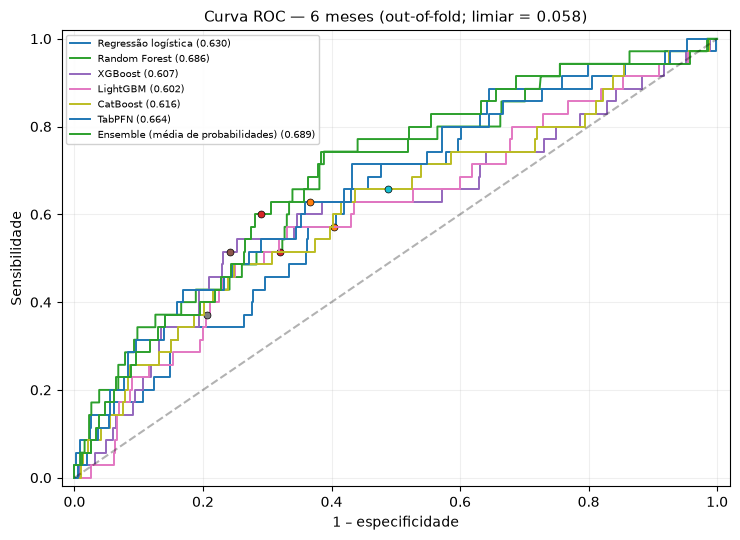

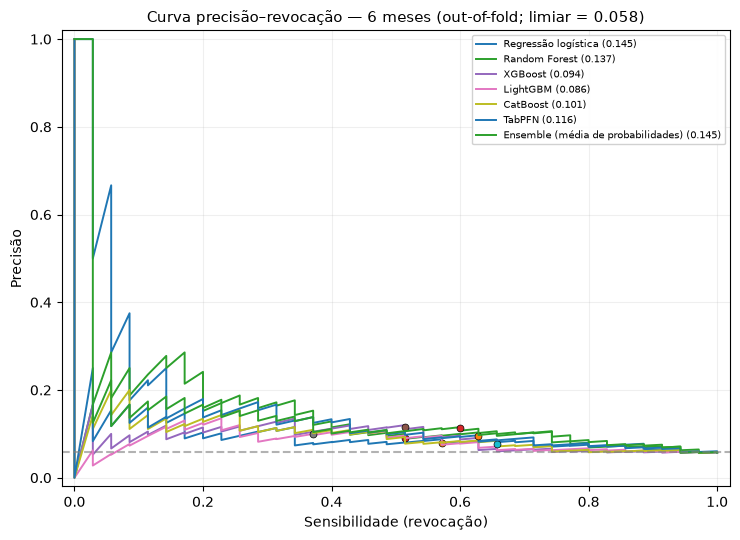

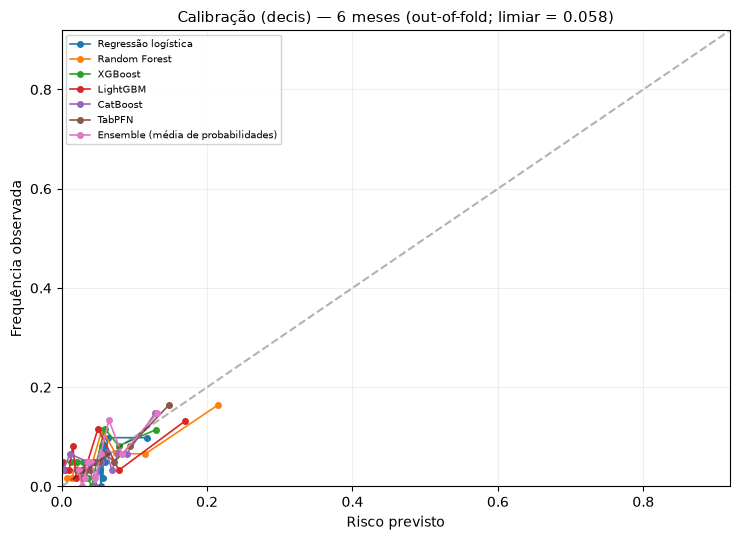

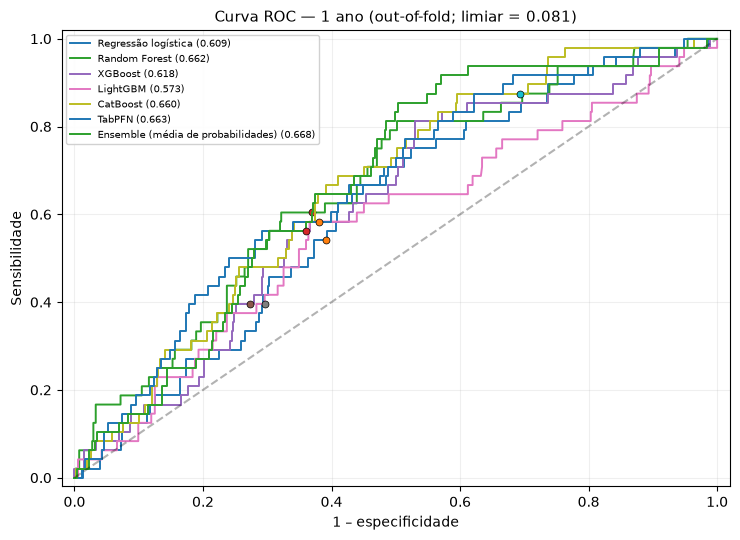

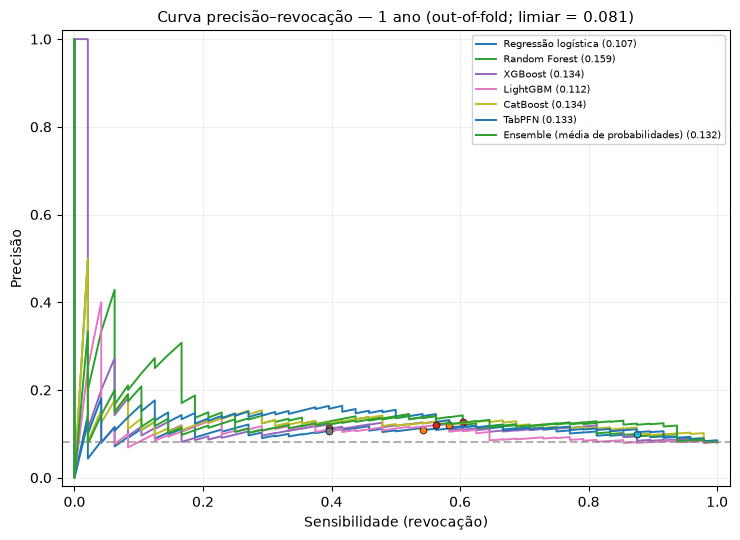

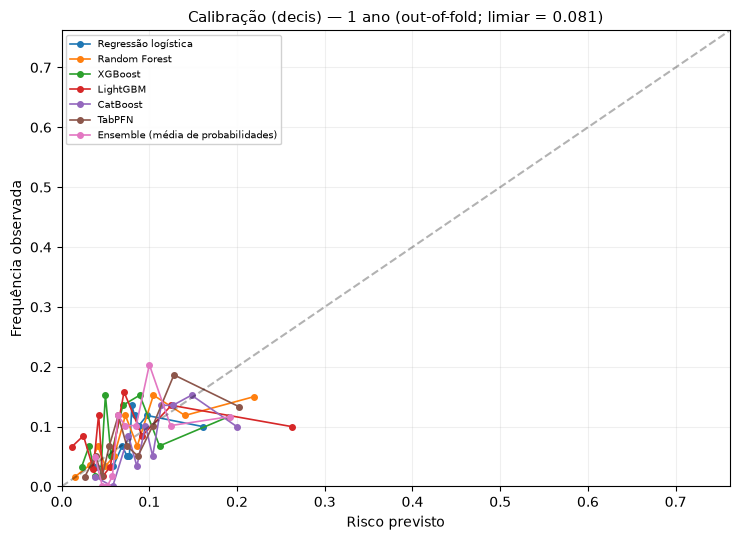

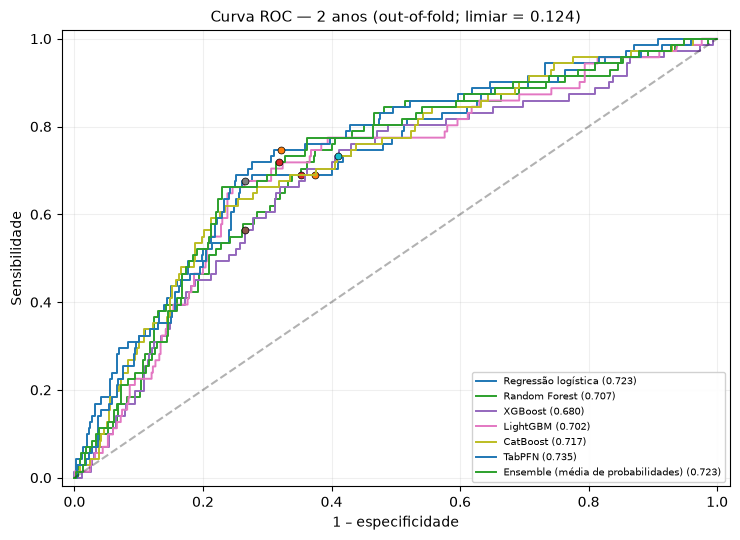

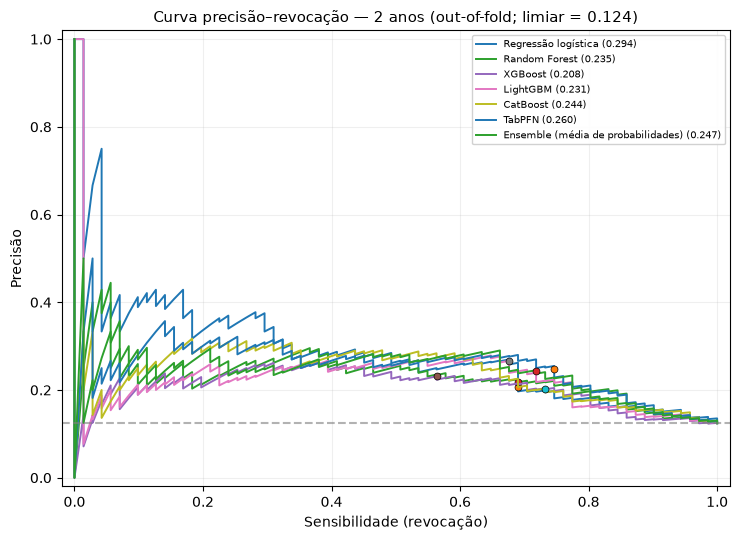

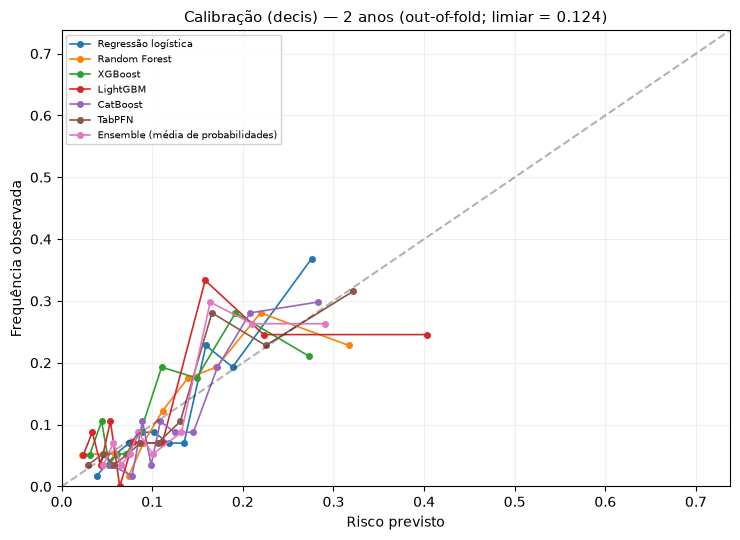

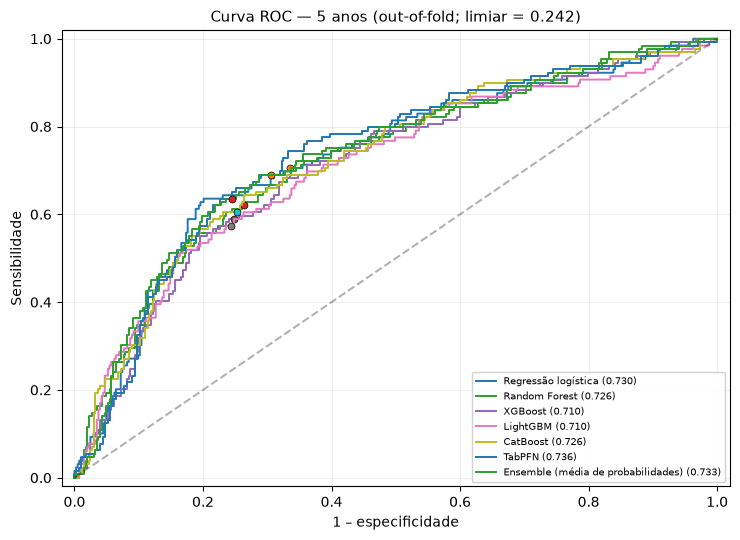

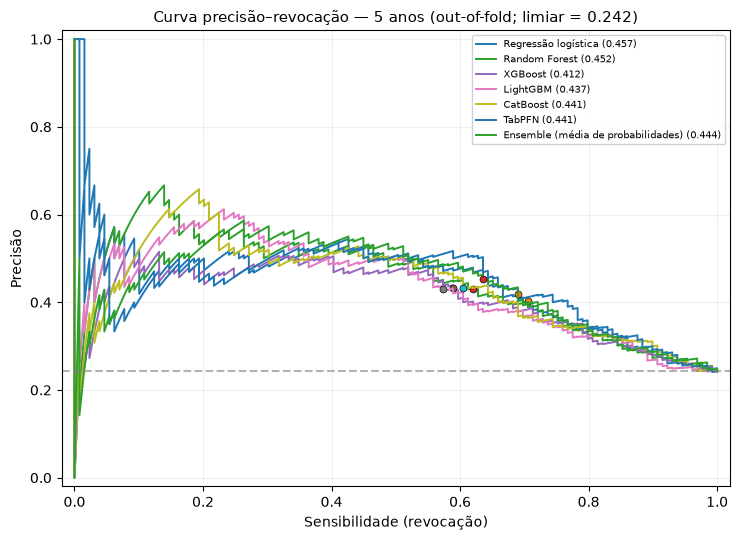

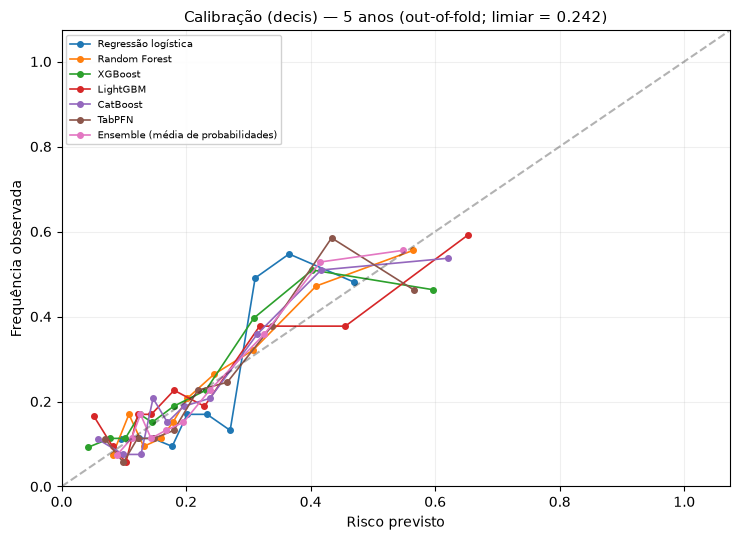

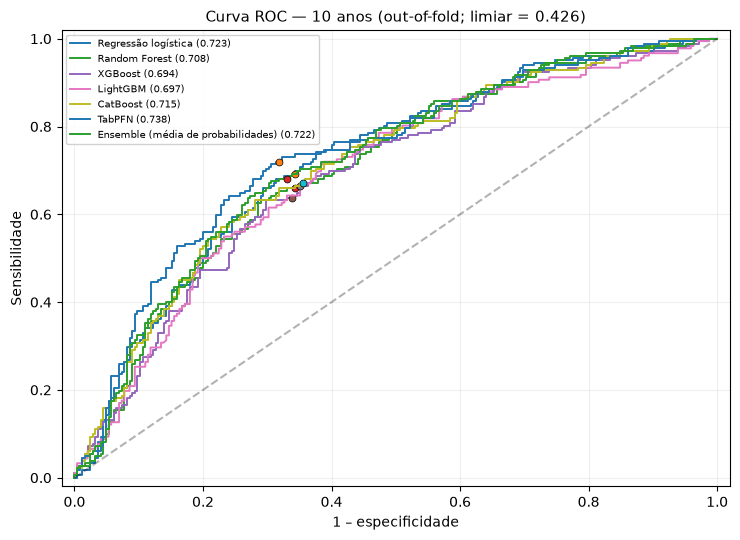

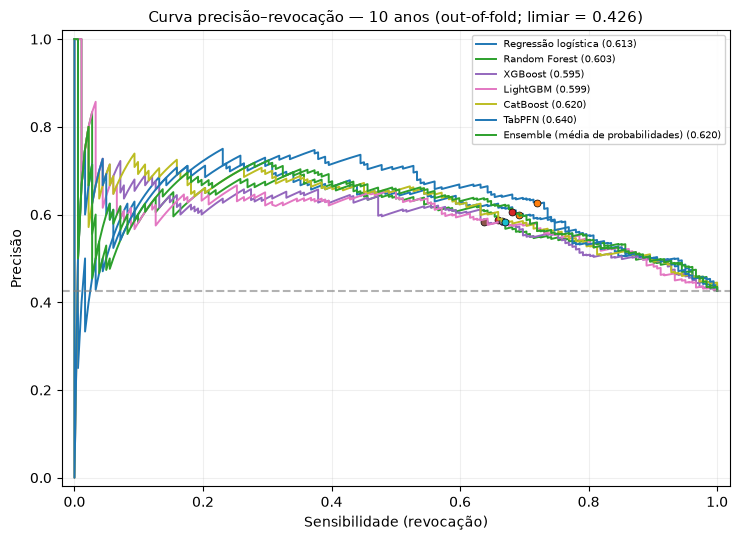

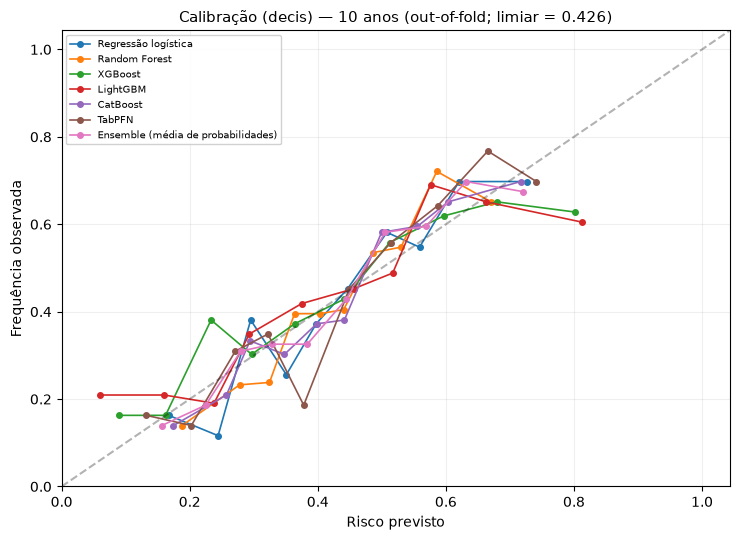

In [50]:
for alvo, obj in PREDICOES.items():
    y, pred = obj['y'], obj['pred']
    prev = float(np.mean(y))          # limiar adotado para este horizonte

    for tipo in ['roc', 'pr', 'calibracao']:
        fig, ax = plt.subplots(figsize=(7.5, 5.5))

        for nome, p in pred.items():
            if tipo == 'roc':
                xx, yy, _ = roc_curve(y, p)
                ax.plot(xx, yy, lw=1.4,
                        label=f'{nome} ({roc_auc_score(y, p):.3f})')
                # Ponto de operação: limiar = prevalência
                cls = (p >= prev).astype(int)
                tn, fp, fn, tp = confusion_matrix(y, cls, labels=[0,1]).ravel()
                ax.plot(fp/(fp+tn), tp/(tp+fn), 'o', ms=5, mec='k', mew=.5)

            elif tipo == 'pr':
                pp, rr, _ = precision_recall_curve(y, p)
                ax.plot(rr, pp, lw=1.4,
                        label=f'{nome} ({average_precision_score(y, p):.3f})')
                cls = (p >= prev).astype(int)
                tn, fp, fn, tp = confusion_matrix(y, cls, labels=[0,1]).ravel()
                if tp + fp > 0:
                    ax.plot(tp/(tp+fn), tp/(tp+fp), 'o', ms=5, mec='k', mew=.5)

            else:
                # Calibração por decis de risco previsto (descritivo).
                data = pd.DataFrame({'p': p, 'y': y})
                try:
                    data['bin'] = pd.qcut(data.p, q=min(10, data.p.nunique()),
                                          duplicates='drop')
                except ValueError:
                    print(f'[aviso] calibração não gerada para {nome} '
                          f'em {ROTULOS[alvo]}: probabilidades sem variação')
                    continue
                g = data.groupby('bin', observed=True).agg(
                    previsto=('p', 'mean'), observado=('y', 'mean'))
                ax.plot(g.previsto, g.observado, 'o-', ms=4, lw=1.2, label=nome)

        if tipo == 'roc':
            ax.plot([0, 1], [0, 1], 'k--', alpha=.3)
            ax.set(xlabel='1 – especificidade', ylabel='Sensibilidade',
                   xlim=(-.02, 1.02), ylim=(-.02, 1.02))
            titulo = 'Curva ROC'

        elif tipo == 'pr':
            ax.axhline(prev, color='gray', ls='--', alpha=.6)
            ax.set(xlabel='Sensibilidade (revocação)', ylabel='Precisão',
                   xlim=(-.02, 1.02), ylim=(-.02, 1.02))
            titulo = 'Curva precisão–revocação'

        else:
            # Limites ajustados aos dados: com desfecho raro, as
            # probabilidades ocupam uma faixa estreita e a escala
            # [0,1] tornaria o gráfico ilegível.
            lim = max(
                max(np.nanmax(p) for p in pred.values()),
                float(np.mean(y)) * 2,
            ) * 1.1
            ax.plot([0, lim], [0, lim], 'k--', alpha=.3)
            ax.set(xlabel='Risco previsto', ylabel='Frequência observada',
                   xlim=(0, lim), ylim=(0, lim))
            titulo = 'Calibração (decis)'

        ax.set_title(f'{titulo} — {ROTULOS[alvo]} '
                     f'(out-of-fold; limiar = {prev:.3f})', fontsize=11)
        ax.legend(fontsize=7, loc='best', framealpha=.9)
        ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(DIR_RESULTADOS / f'fig_{tipo}_{alvo}.png', dpi=240)
        plt.show()
        plt.close(fig)

## 9. Interpretabilidade e ajustes finais

Importância de variáveis em modelos reajustados na coorte completa serve para **descrição/exploração**, e não constitui desempenho independente — este permanece ancorado nas predições OOF. O SHAP do TabPFN usa `KernelExplainer`, que é aproximado e computacionalmente caro; a amostra explicada é estratificada por desfecho, de modo que sua proporção de eventos não corresponde à da coorte. Para uso prospectivo, o modelo final precisa ser reconstruído no conjunto completo com hiperparâmetros escolhidos exclusivamente por validação interna.


>>> 6 meses
    amostra SHAP: 85 pacientes (35 eventos)


100%|██████████| 85/85 [24:41<00:00, 17.43s/it]


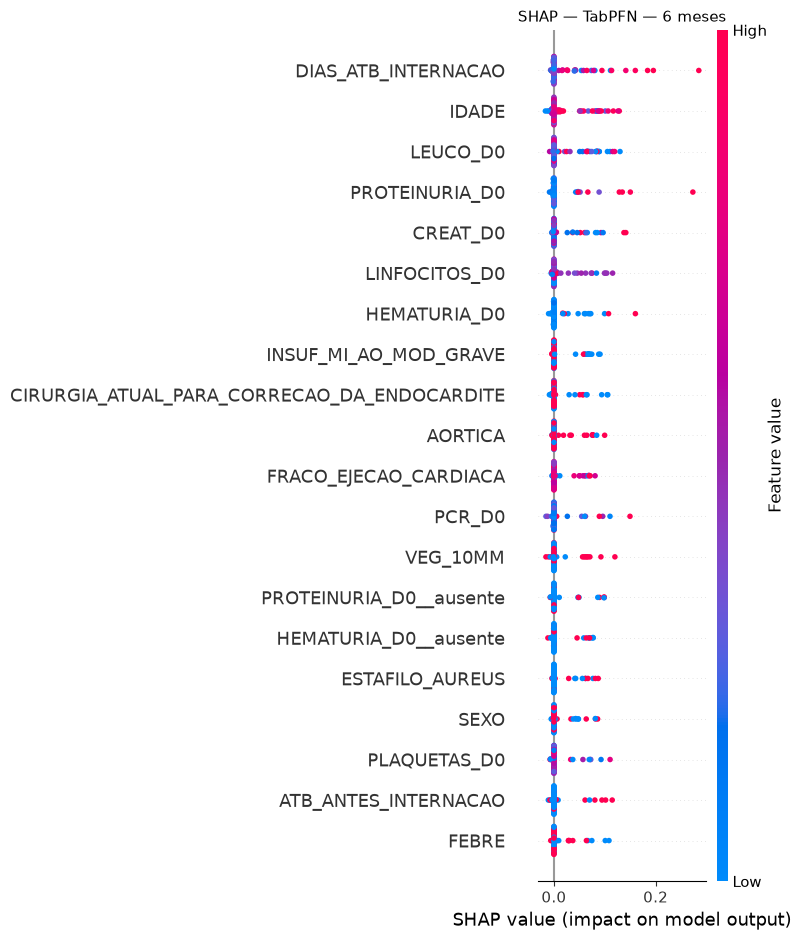

    24.7 min

>>> 1 ano
    amostra SHAP: 98 pacientes (48 eventos)


100%|██████████| 98/98 [28:36<00:00, 17.52s/it]


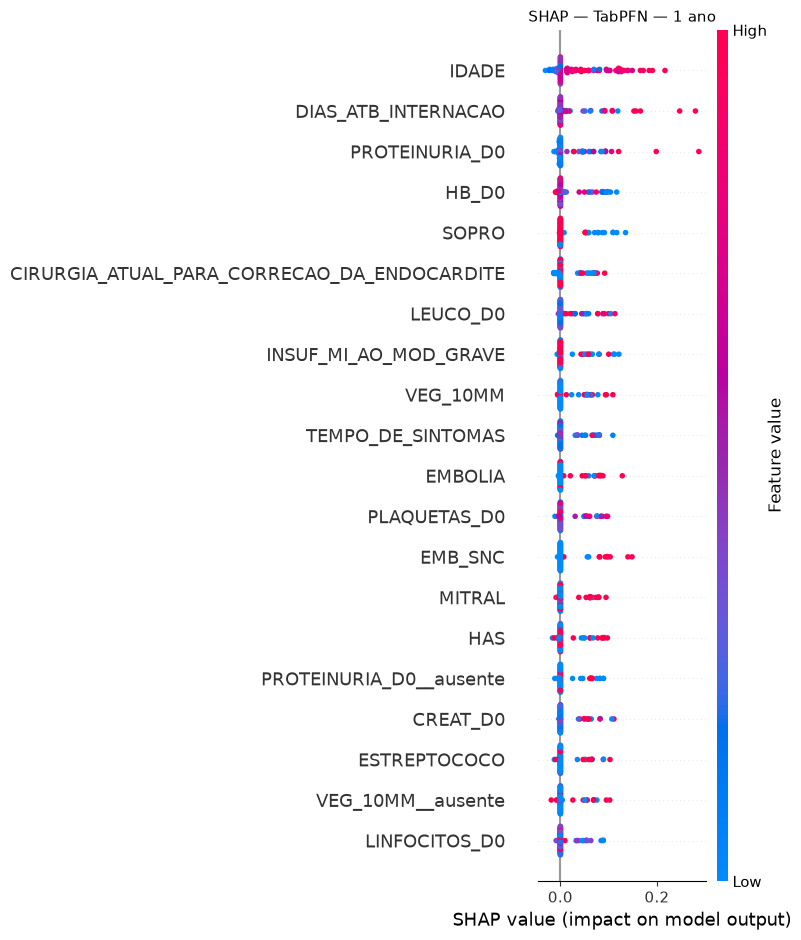

    28.6 min

>>> 2 anos
    amostra SHAP: 100 pacientes (50 eventos)


100%|██████████| 100/100 [29:13<00:00, 17.53s/it]


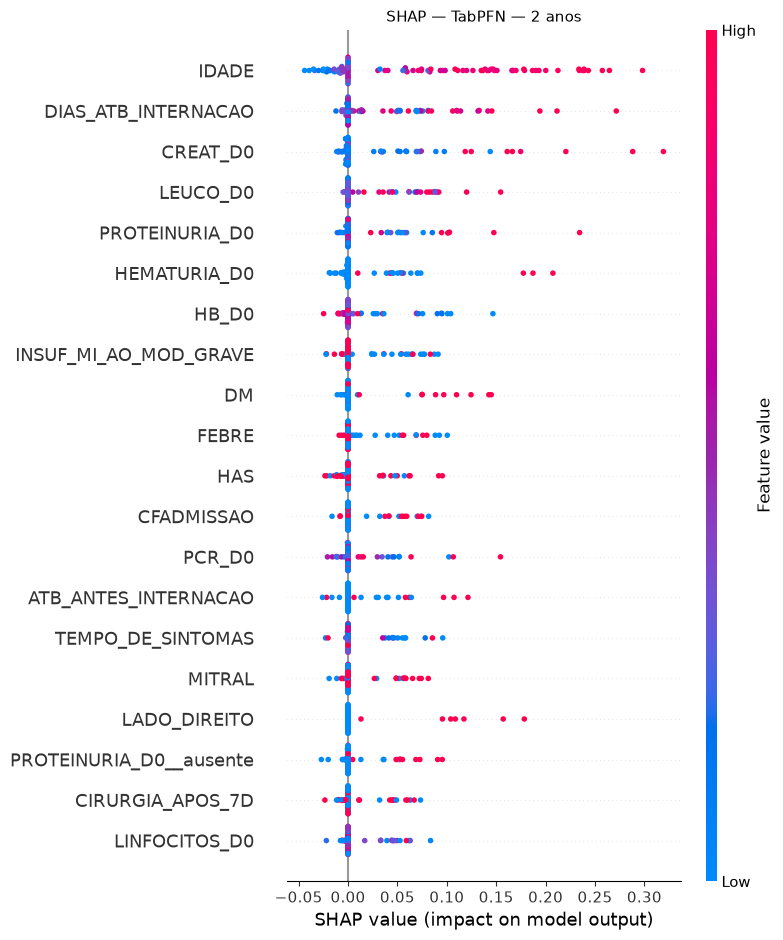

    29.2 min

>>> 5 anos
    amostra SHAP: 100 pacientes (50 eventos)


100%|██████████| 100/100 [29:07<00:00, 17.47s/it]


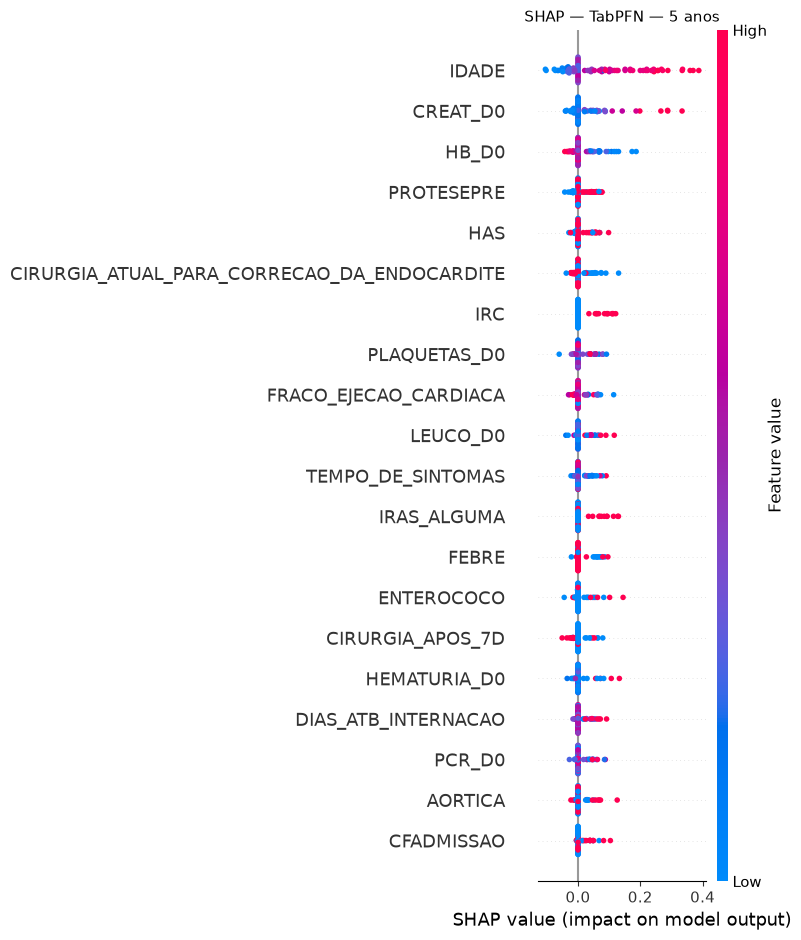

    29.1 min

>>> 10 anos
    amostra SHAP: 100 pacientes (50 eventos)


100%|██████████| 100/100 [11:37<00:00,  6.98s/it]


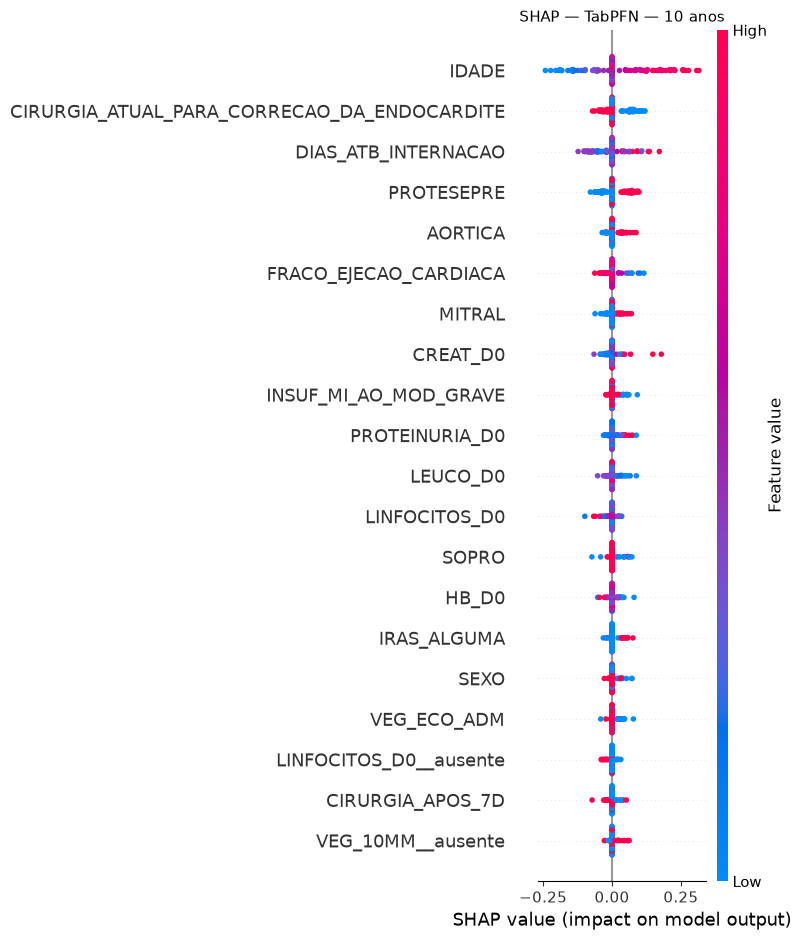

    11.7 min


horizonte,6 meses,1 ano,2 anos,5 anos,10 anos
variavel,,,,,
IDADE,0.0209,0.0466,0.0766,0.0888,0.0926
CIRURGIA_ATUAL_PARA_CORRECAO_DA_ENDOCARDITE,0.0087,0.0115,0.0070,0.0125,0.0372
DIAS_ATB_INTERNACAO,0.0239,0.0198,0.0289,0.0077,0.0347
PROTESEPRE,0.0043,0.0038,0.0071,0.0160,0.0347
AORTICA,0.0086,0.0066,0.0064,0.0075,0.0136
FRACO_EJECAO_CARDIACA,0.0084,0.0038,0.0063,0.0105,0.0130
MITRAL,0.0056,0.0099,0.0078,0.0060,0.0121
CREAT_D0,0.0124,0.0082,0.0264,0.0324,0.0118
INSUF_MI_AO_MOD_GRAVE,0.0098,0.0112,0.0119,0.0055,0.0104


In [52]:
# ═══════════════════════════════════════════════════════════════════════
# 9. Interpretabilidade — TabPFN via KernelExplainer
#
#    Modelo reajustado na coorte completa, apenas para DESCREVER quais
#    variáveis pesam. Não é estimativa de desempenho: essa vem do OOF.
#
#    KernelExplainer é agnóstico ao modelo (necessário para o TabPFN,
#    que não é baseado em árvores), mas caro: aproxima os valores SHAP
#    chamando o modelo milhares de vezes. Os três parâmetros abaixo
#    controlam diretamente o tempo de execução.
# ═══════════════════════════════════════════════════════════════════════

N_EXPLICAR   = 100   # pacientes que recebem valores SHAP (metade por classe)
N_BACKGROUND = 50    # referência do KernelExplainer (k-means sobre a coorte)
N_SAMPLES    = 200   # perturbações por paciente; 'auto' é muito mais lento

# Para cronometrar antes de rodar tudo, use ['OBITO_1A'] aqui.
HORIZONTES_SHAP = HORIZONTES_RODAR

importancias = []

for alvo in HORIZONTES_SHAP:
    print(f'\n>>> {ROTULOS[alvo]}')
    t0 = time.time()

    X, y, _ = COORTES[alvo]

    # Pré-processamento ajustado na coorte inteira: aqui não há teste a
    # proteger, o objetivo é descritivo.
    pp = PreProcessador().fit(X)
    Z = pp.transform(X)

    model = criar_modelo('TabPFN', {}, SEED)
    model.fit(Z, y)

    # Background resumido por k-means: o KernelExplainer compara cada
    # predição contra essa referência.
    fundo = shap.kmeans(Z, N_BACKGROUND)

    # Amostra estratificada por posição. Sem estratificar, em 6 meses
    # quase só não-eventos seriam sorteados e o gráfico não mostraria
    # o que separa os dois grupos.
    rng = np.random.default_rng(SEED)
    n_cada = N_EXPLICAR // 2
    idx_ev  = np.flatnonzero(y == 1)
    idx_nev = np.flatnonzero(y == 0)
    sel = np.r_[
        rng.choice(idx_ev,  min(len(idx_ev),  n_cada), replace=False),
        rng.choice(idx_nev, min(len(idx_nev), n_cada), replace=False),
    ]
    amostra = Z.iloc[sel]
    print(f'    amostra SHAP: {len(amostra)} pacientes '
          f'({(y[sel] == 1).sum()} eventos)')

    explainer = shap.KernelExplainer(
        lambda d: model.predict_proba(pd.DataFrame(d, columns=Z.columns))[:, 1],
        fundo)
    vals = np.asarray(explainer.shap_values(amostra, nsamples=N_SAMPLES))
    if vals.ndim == 3:
        vals = vals[:, :, 1]

    plt.figure()
    shap.summary_plot(vals, amostra, show=False, max_display=20)
    plt.title(f'SHAP — TabPFN — {ROTULOS[alvo]}', fontsize=11)
    plt.tight_layout()
    plt.savefig(DIR_RESULTADOS / f'fig_shap_TabPFN_{alvo}.png', dpi=240)
    plt.show()
    plt.close()

    importancias.append(pd.DataFrame({
        'horizonte': ROTULOS[alvo],
        'variavel': amostra.columns,
        'shap_medio_abs': np.abs(vals).mean(axis=0),
    }))

    print(f'    {(time.time() - t0) / 60:.1f} min')

shap_tab = pd.concat(importancias, ignore_index=True)
salvar_csv(shap_tab, '11_shap_importancias_tabpfn.csv')

# Ranking lado a lado: mostra se os preditores mudam entre horizontes.
pivot = (shap_tab.pivot(index='variavel', columns='horizonte',
                        values='shap_medio_abs')
         .reindex(columns=[ROTULOS[a] for a in HORIZONTES_SHAP]))
display(pivot.sort_values(pivot.columns[-1], ascending=False).head(20).round(4))

## 10. Registro TRIPOD+AI e checklist para o manuscrito

**Dados a complementar manualmente no artigo:** desenho do estudo, centro de recrutamento, elegibilidade, datas, origem dos dados, protocolo/ética, cálculo de tamanho amostral, definição clínica dos preditores, viés de seleção por exclusões, representatividade e utilidade clínica; também requer descrição dos potenciais fatores de viés e validação externa quando disponível.

In [ ]:
CHECKLIST = [
('População','Fluxo, elegibilidade e eventos por horizonte','03_fluxo_por_horizonte.csv'),
('Desfecho','Óbito após a alta por horizonte; auditado contra tempo e evento','auditado na seção 3'),
('Preditores','Exclusões automáticas + revisão clínica necessária','01_auditoria_variaveis.csv'),
('Dados ausentes','Quantificação, limites e imputação dentro de folds','02_dados_ausentes.csv'),
('Modelos','Algoritmos, parâmetros, semente e espaços de busca','05_hiperparametros_folds.csv'),
('Validação','Estratificada 5 folds externos / 5 internos; sem vazamento de tuning','04_predicoes_oof_*.csv'),
('Discriminação e calibração','AUROC, AUPRC, Brier, intercepto e inclinação','08_metricas_ic95.csv'),
('Ponto de operação','Limiar = prevalência do horizonte; curva completa reportada','09_curva_limiares.csv; 10_limiar_prevalencia.csv'),
('Interpretabilidade','SHAP (KernelExplainer) sobre TabPFN reajustado na coorte completa','11_shap_importancias_tabpfn.csv'),
('Reprodutibilidade','Versões, definições e parâmetros','13_ambiente_config.json'),
('Limitações','Exclusão por seguimento insuficiente, amostra única, ausência de validação externa','descrever no artigo')]

salvar_csv(pd.DataFrame(CHECKLIST, columns=['dimensao','registro','arquivo']),
           '12_checklist_tripod_ai.csv')

registro = {
    'data_execucao': date.today().isoformat(),
    'semente': SEED,
    'versoes': VERSOES,
    'horizontes_dias': HORIZONTES,
    'N_trials': N_TRIALS,
    'folds_externos': N_SPLITS_EXTERNO,
    'folds_internos': N_SPLITS_INTERNO,
    'N_boot': N_BOOT,
    'limiar_referencia': LIMIAR_REFERENCIA,
    'ponto_de_operacao': 'prevalência do horizonte (regra a priori)',
    'modelos': MODELOS,
    'ensemble': 'média simples das probabilidades OOF dos modelos listados',
    'selecao_de_variaveis': 'nenhuma — todas as candidatas entram nos modelos',
    'ponderacao_de_classe': BALANCEAR_CLASSES,
    'sem_IPCW': True,
}
(DIR_RESULTADOS/'13_ambiente_config.json').write_text(
    json.dumps(registro, ensure_ascii=False, indent=2), encoding='utf8')

print('Resultados em:', DIR_RESULTADOS.resolve())
print('ATENÇÃO: validação interna não equivale a validação externa. '
      'Conferir manualmente elegibilidade, momento de predição e '
      'concordância dos desfechos.')